# 03 — Modelling: comparison of five machine-learning models

| # | Model | Family |
|---|---|---|
| 1 | Logistic regression | Linear model (baseline credit scorecard) |
| 2 | Decision tree | Single tree |
| 3 | Random forest | Bagging of trees |
| 4 | XGBoost | Gradient boosting of trees |
| 5 | LightGBM | Gradient boosting of trees (main model) |

Steps:
1. Stratified 80/20 train/holdout split by `SK_ID_CURR`, created once and saved (`data/processed/split_ids.parquet`).
2. Every model is tuned (where applicable) on the training set and scored with **5-fold stratified CV on train**;
   the CV out-of-fold (OOF) predictions are kept for threshold selection. Training time of the final fit is recorded.
3. Each model's **cost-optimal threshold** is chosen on its training OOF predictions with the cost function in
   `src/cost.py` (approving a defaulter costs 0.60 × `AMT_CREDIT`, rejecting a good applicant 0.15 × `AMT_CREDIT`).
4. **One** holdout evaluation per model, at threshold 0.5 and at its cost-optimal threshold, with the same nine
   metrics; comparison charts; metric-vs-threshold curves; an overfitting check (train vs CV vs holdout AUC).

**Leakage controls:** the holdout is never used for fitting, tuning, imputation, scaling, early stopping or threshold
choice. Logistic-regression, decision-tree and random-forest preprocessing is inside sklearn `Pipeline`s, refitted in
every CV fold. Shared code: `src/modeling.py`, `src/cost.py`, `src/thresholds.py`.

### Why these five models

| Model | Why it is in the comparison |
|---|---|
| Logistic regression | The industry-standard credit scorecard: one coefficient per input, easy to explain to customers and regulators. It is the baseline every other model has to beat. |
| Decision tree | The most interpretable non-linear model: a short list of if-then questions that can be drawn and read. Shows what a single tree can and cannot do, and is the building block of the next three models. |
| Random forest | Many deep trees on random subsets of applicants and features, averaged (*bagging*). Averaging reduces the variance of single trees; captures interactions without feature scaling. |
| XGBoost | Gradient boosting: shallow trees added one at a time, each correcting the errors of the ones before. Handles missing values and categorical features natively. Kept with fixed (untuned) parameters from the original analysis. |
| LightGBM | Gradient boosting with leaf-wise trees and histogram binning: very fast on 246,005 × 161 data, native missing values and categoricals, tuned by random search. The main model. |

Together they span the bias–variance spectrum: a linear model (high bias), a single tree (high variance unless
pruned), bagging (reduces variance) and boosting (reduces bias step by step, with regularisation against variance).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, ParameterSampler, StratifiedKFold, cross_validate
from sklearn.tree import plot_tree

from src.config import ID, MODELS_DIR, PROCESSED_DIR, RANDOM_STATE, REPORTS_DIR, TARGET
from src.cost import approve_all_cost, decision_summary, optimal_threshold, threshold_sweep
from src.modeling import (METRICS, categorical_columns, cross_validate_gbm, cross_validate_sklearn, evaluate,
                          feature_columns, fit_lgbm, fit_xgb, load_or_create_split, make_dt_pipeline,
                          make_logreg_pipeline, make_rf_pipeline, metric_row, train_holdout)
from src.plotting import DEFAULT, INK_2, MUTED, SEQ_BLUE, SERIES, plot_confusion, savefig, set_style
from src.thresholds import CURVE_THRESHOLDS, metrics_by_threshold

set_style()
pd.set_option("display.max_columns", 40, "display.width", 180)
MODELS_DIR.mkdir(exist_ok=True)
MODEL_ORDER = ["Logistic regression", "Decision tree", "Random forest", "XGBoost", "LightGBM"]
MODEL_COLORS = {"Logistic regression": SERIES[0], "Decision tree": SERIES[4], "Random forest": SERIES[3],
                "XGBoost": SERIES[2], "LightGBM": SERIES[1]}
SHORT = {"Logistic regression": "logreg", "Decision tree": "dt", "Random forest": "rf", "XGBoost": "xgb",
         "LightGBM": "lgbm"}
fit_seconds = {}  # wall-clock time of each model's final fit on the full training set

## 1. Train / holdout split

In [2]:
model_table = pd.read_parquet(PROCESSED_DIR / "model_table.parquet")
split, created = load_or_create_split(model_table)
print("split file:", "created now" if created else "loaded (created earlier, not re-drawn)")
train, holdout = train_holdout(model_table, split)

split_summary = pd.DataFrame({
    "applicants": [len(train), len(holdout)],
    "defaults": [int(train[TARGET].sum()), int(holdout[TARGET].sum())],
    "default_rate": [train[TARGET].mean(), holdout[TARGET].mean()],
}, index=["train (80%)", "holdout (20%)"])
display(split_summary.style.format({"applicants": "{:,}", "defaults": "{:,}", "default_rate": "{:.4%}"}))
assert not set(train[ID]) & set(holdout[ID])

FEATURES = feature_columns(model_table)
CAT_COLS = categorical_columns(model_table[FEATURES])
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
X_train, y_train = train[FEATURES], train[TARGET]
X_holdout, y_holdout = holdout[FEATURES], holdout[TARGET]
print(f"features: {len(FEATURES)} ({len(NUM_COLS)} numeric, {len(CAT_COLS)} categorical)")

split file: loaded (created earlier, not re-drawn)


,applicants,defaults,default_rate
train (80%),"246,005","19,860",8.0730%
holdout (20%),"61,502","4,965",8.0729%


features: 161 (145 numeric, 16 categorical)


## 2. Model 1 — Logistic regression (baseline)
Median imputation + missing-value indicators and `StandardScaler` for numeric columns; constant imputation and
`OneHotEncoder(handle_unknown='ignore', min_frequency=0.01)` for categoricals; `class_weight='balanced'`,
`max_iter=2000`. The whole pipeline is refitted inside each CV fold; the out-of-fold predictions are kept for threshold selection.

In [3]:
t0 = time.time()
lr_cv = cross_validate_sklearn(make_logreg_pipeline(NUM_COLS, CAT_COLS), X_train, y_train, n_jobs=5)
lr_cv_auc = np.array(lr_cv["fold_aucs"])
print(f"Logistic regression 5-fold CV AUC: {lr_cv_auc.mean():.4f} ± {lr_cv_auc.std():.4f} "
      f"(folds: {np.round(lr_cv_auc, 4).tolist()}) [{time.time() - t0:.0f}s]")

t0 = time.time()
logreg = make_logreg_pipeline(NUM_COLS, CAT_COLS).fit(X_train, y_train)
fit_seconds["Logistic regression"] = time.time() - t0
n_inputs = logreg.named_steps["pre"].transform(X_train.head(1)).shape[1]
print(f"final fit on full train: {time.time() - t0:.0f}s, iterations: {logreg[-1].n_iter_[0]}, "
      f"model inputs after preprocessing: {n_inputs}")

Logistic regression 5-fold CV AUC: 0.7600 ± 0.0013 (folds: [0.7593, 0.7619, 0.761, 0.7586, 0.7591]) [36s]


final fit on full train: 19s, iterations: 225, model inputs after preprocessing: 325


## 3. Model 5 — LightGBM (main model)

Random search over the requested hyperparameters, each candidate scored by 5-fold stratified CV on the training
set. Early stopping (100 rounds, AUC) uses a stratified 10% carve-out of each fold's *training* part, so the CV
fold being scored is never seen during fitting. `scale_pos_weight` = negatives/positives of the fitting data.
The search is bounded by `N_TRIALS` and a wall-clock budget. (sklearn-API names: `colsample_bytree` =
feature_fraction, `subsample` = bagging_fraction.)

In [4]:
SEARCH_SPACE = {
    "learning_rate": [0.02, 0.03, 0.05, 0.1],
    "num_leaves": [15, 31, 63, 127],
    "min_child_samples": [20, 50, 100, 200, 400],
    "colsample_bytree": [0.3, 0.5, 0.7, 0.9],
    "subsample": [0.6, 0.8, 1.0],
    "reg_lambda": [0, 1, 5, 10, 30],
}
N_TRIALS = 20
TIME_BUDGET_MIN = 40

candidates = list(ParameterSampler(SEARCH_SPACE, n_iter=N_TRIALS, random_state=RANDOM_STATE))
search_rows, search_cv = [], {}
t_search = time.time()
for i, params in enumerate(candidates):
    if (time.time() - t_search) / 60 > TIME_BUDGET_MIN:
        print(f"time budget of {TIME_BUDGET_MIN} min reached after {i} trials")
        break
    cv = cross_validate_gbm(fit_lgbm, params, X_train, y_train)
    search_cv[i] = cv
    search_rows.append({"trial": i, **params, "cv_auc_mean": cv["auc_mean"], "cv_auc_std": cv["auc_std"],
                        "mean_best_iteration": float(np.mean(cv["best_iterations"])), "seconds": cv["seconds"]})
    print(f"trial {i:>2}: CV AUC {cv['auc_mean']:.4f} ± {cv['auc_std']:.4f}  ({cv['seconds']:.0f}s)  {params}")
print(f"search finished: {len(search_rows)} trials in {(time.time() - t_search) / 60:.1f} min")

search_results = pd.DataFrame(search_rows).sort_values("cv_auc_mean", ascending=False)
search_results.to_csv(REPORTS_DIR / "lgbm_search_results.csv", index=False)
display(search_results.head(10).round(4))

trial  0: CV AUC 0.7749 ± 0.0013  (27s)  {'subsample': 1.0, 'reg_lambda': 1, 'num_leaves': 31, 'min_child_samples': 400, 'learning_rate': 0.05, 'colsample_bytree': 0.3}


trial  1: CV AUC 0.7737 ± 0.0016  (94s)  {'subsample': 0.8, 'reg_lambda': 5, 'num_leaves': 127, 'min_child_samples': 100, 'learning_rate': 0.02, 'colsample_bytree': 0.9}


trial  2: CV AUC 0.7714 ± 0.0019  (36s)  {'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 63, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


trial  3: CV AUC 0.7733 ± 0.0019  (43s)  {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 127, 'min_child_samples': 100, 'learning_rate': 0.03, 'colsample_bytree': 0.3}


trial  4: CV AUC 0.7693 ± 0.0024  (36s)  {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 127, 'min_child_samples': 200, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


trial  5: CV AUC 0.7694 ± 0.0018  (16s)  {'subsample': 0.6, 'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 100, 'learning_rate': 0.1, 'colsample_bytree': 0.7}


... (11 outputs left out)

trial 17: CV AUC 0.7736 ± 0.0012  (33s)  {'subsample': 0.6, 'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 200, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


trial 18: CV AUC 0.7727 ± 0.0014  (35s)  {'subsample': 0.6, 'reg_lambda': 10, 'num_leaves': 127, 'min_child_samples': 100, 'learning_rate': 0.03, 'colsample_bytree': 0.3}


trial 19: CV AUC 0.7728 ± 0.0019  (19s)  {'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 15, 'min_child_samples': 200, 'learning_rate': 0.1, 'colsample_bytree': 0.3}
search finished: 20 trials in 11.6 min


,trial,subsample,reg_lambda,num_leaves,min_child_samples,learning_rate,colsample_bytree,cv_auc_mean,cv_auc_std,mean_best_iteration,seconds
8,8,0.8,10,15,100,0.02,0.3,0.7758,0.0015,1215.6,48.0030
0,0,1.0,1,31,400,0.05,0.3,0.7749,0.0013,406.6,27.2515
9,9,1.0,1,15,200,0.03,0.5,0.7748,0.0015,990.8,46.5394
1,1,0.8,5,127,100,0.02,0.9,0.7737,0.0016,491.4,93.7394
17,17,0.6,10,31,200,0.03,0.7,0.7736,0.0012,492.4,32.6104
16,16,0.8,5,63,200,0.03,0.9,0.7735,0.0017,390.4,42.0877
7,7,0.6,10,63,200,0.03,0.7,0.7733,0.0011,392.8,36.5522
3,3,0.8,0,127,100,0.03,0.3,0.7733,0.0019,367.0,42.6158
12,12,0.6,1,63,20,0.02,0.7,0.7729,0.0014,550.6,46.8544
19,19,1.0,0,15,200,0.10,0.3,0.7728,0.0019,314.4,18.8286


In [5]:
best_trial = int(search_results.iloc[0]["trial"])
best_params = candidates[best_trial]
lgbm_cv = search_cv[best_trial]
print("best parameters:", best_params)
print(f"LightGBM 5-fold CV AUC: {lgbm_cv['auc_mean']:.4f} ± {lgbm_cv['auc_std']:.4f} "
      f"(folds: {np.round(lgbm_cv['fold_aucs'], 4).tolist()}); best iterations per fold: {lgbm_cv['best_iterations']}")

t0 = time.time()
lgbm = fit_lgbm(best_params, X_train, y_train)
fit_seconds["LightGBM"] = time.time() - t0
print(f"final LightGBM fit on train (early stopping on a 10% carve-out of train): {time.time() - t0:.0f}s, "
      f"best iteration {lgbm.best_iteration_}")

best parameters: {'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 15, 'min_child_samples': 100, 'learning_rate': 0.02, 'colsample_bytree': 0.3}
LightGBM 5-fold CV AUC: 0.7758 ± 0.0015 (folds: [0.7745, 0.7763, 0.7784, 0.7742, 0.7757]); best iterations per fold: [1131, 1104, 1531, 785, 1527]


final LightGBM fit on train (early stopping on a 10% carve-out of train): 18s, best iteration 2203


## 4. Model 4 — XGBoost (fixed parameters)
Fixed, untuned parameters chosen to be broadly comparable with the LightGBM search space; same imbalance
handling, early-stopping scheme and 5-fold CV.

In [6]:
XGB_PARAMS = dict(learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8, colsample_bytree=0.5,
                  reg_lambda=1.0)
xgb_cv = cross_validate_gbm(fit_xgb, XGB_PARAMS, X_train, y_train)
print(f"XGBoost 5-fold CV AUC: {xgb_cv['auc_mean']:.4f} ± {xgb_cv['auc_std']:.4f} "
      f"(folds: {np.round(xgb_cv['fold_aucs'], 4).tolist()}) [{xgb_cv['seconds']:.0f}s]")
t0 = time.time()
xgb = fit_xgb(XGB_PARAMS, X_train, y_train)
fit_seconds["XGBoost"] = time.time() - t0
print(f"final XGBoost best iteration: {xgb.best_iteration + 1}")

XGBoost 5-fold CV AUC: 0.7698 ± 0.0017 (folds: [0.7692, 0.7691, 0.7729, 0.7679, 0.77]) [71s]


final XGBoost best iteration: 333


**Insight (cross-validation on train, logistic regression and the two boosting models):** LightGBM is the strongest model in 5-fold CV (AUC 0.7758 ± 0.0015), ahead of
the untuned XGBoost (0.7698 ± 0.0017) and the logistic-regression scorecard (0.7600 ± 0.0013). Fold-to-fold spread is
at most 0.0017, so the ranking is stable. The random search tried 20 configurations in 11.2 minutes (wall-clock time varies slightly between runs), with CV AUC from
0.7641 to 0.7758. The best configuration uses many small, heavily regularised trees: `num_leaves` = 15,
`learning_rate` = 0.02, `colsample_bytree` (feature_fraction) = 0.3, `subsample` (bagging_fraction) = 0.8,
`min_child_samples` = 100 and `reg_lambda` = 10.

## 5. Model 2 — Decision tree

**How it works:** the tree asks a sequence of yes/no questions about one feature at a time ("is `EXT_SOURCE_MEAN`
below 0.4?"), choosing at every step the split that best separates defaulters from good applicants (Gini impurity).
Each leaf's score is the (class-weighted) share of defaulters among the training applicants that reach it.

**Preprocessing (inside the pipeline):** median imputation for numeric columns (splits are thresholds, so no scaling
is needed) and `OneHotEncoder(handle_unknown='ignore', min_frequency=0.01)` for categoricals, because sklearn trees
need numeric input. **Imbalance:** `class_weight='balanced'` counts each default about 11 times as much as a repaid
loan when choosing splits.

**Tuning:** grid search over `max_depth` {4, 6, 8, 10, 12} × `min_samples_leaf` {50, 100, 200} with 3-fold
stratified CV AUC on the training set (training-fold AUCs are kept to show under- and overfitting).

In [7]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
DT_GRID = {"model__max_depth": [4, 6, 8, 10, 12], "model__min_samples_leaf": [50, 100, 200]}
t0 = time.time()
dt_search = GridSearchCV(make_dt_pipeline(NUM_COLS, CAT_COLS), DT_GRID, scoring="roc_auc", cv=cv3, n_jobs=5,
                         return_train_score=True).fit(X_train, y_train)
dt_results = pd.DataFrame(dt_search.cv_results_)[["param_model__max_depth", "param_model__min_samples_leaf",
                                                   "mean_train_score", "mean_test_score", "std_test_score",
                                                   "mean_fit_time"]]
dt_results.columns = ["max_depth", "min_samples_leaf", "train_auc_mean", "cv3_auc_mean", "cv3_auc_std",
                      "fit_seconds_mean"]
dt_results = dt_results.sort_values("cv3_auc_mean", ascending=False)
dt_results.to_csv(REPORTS_DIR / "dt_search_results.csv", index=False)
print(f"grid search: {len(dt_results)} configurations x 3 folds in {time.time() - t0:.0f}s")
display(dt_results.round(4))
dt_best_params = {k.replace("model__", ""): v for k, v in dt_search.best_params_.items()}
print("best decision-tree parameters:", dt_best_params)

grid search: 15 configurations x 3 folds in 155s


,max_depth,min_samples_leaf,train_auc_mean,cv3_auc_mean,cv3_auc_std,fit_seconds_mean
5,6,200,0.7408,0.7229,0.0005,11.8225
4,6,100,0.7410,0.7228,0.0008,11.8319
3,6,50,0.7411,0.7223,0.0010,12.0098
8,8,200,0.7609,0.7208,0.0008,13.3673
7,8,100,0.7641,0.7190,0.0006,13.3933
2,4,200,0.7241,0.7163,0.0007,9.9523
1,4,100,0.7241,0.7163,0.0007,10.0443
0,4,50,0.7241,0.7163,0.0007,10.1695
6,8,50,0.7656,0.7151,0.0021,13.6011
11,10,200,0.7800,0.7129,0.0008,14.4317


best decision-tree parameters: {'max_depth': 6, 'min_samples_leaf': 200}


In [8]:
dt_cv = cross_validate_sklearn(make_dt_pipeline(NUM_COLS, CAT_COLS, **dt_best_params), X_train, y_train, n_jobs=5)
print(f"Decision tree 5-fold CV AUC: {dt_cv['auc_mean']:.4f} ± {dt_cv['auc_std']:.4f} "
      f"(folds: {np.round(dt_cv['fold_aucs'], 4).tolist()})")
t0 = time.time()
dt = make_dt_pipeline(NUM_COLS, CAT_COLS, **dt_best_params).fit(X_train, y_train)
fit_seconds["Decision tree"] = time.time() - t0
tree = dt.named_steps["model"]
print(f"final fit on full train: {fit_seconds['Decision tree']:.0f}s; depth {tree.get_depth()}, "
      f"{tree.get_n_leaves()} leaves, {tree.n_features_in_} model inputs after preprocessing")

Decision tree 5-fold CV AUC: 0.7266 ± 0.0022 (folds: [0.726, 0.7294, 0.7236, 0.7252, 0.7288])


final fit on full train: 17s; depth 6, 64 leaves, 234 model inputs after preprocessing


saved reports/figures/33_decision_tree_top3_levels.png


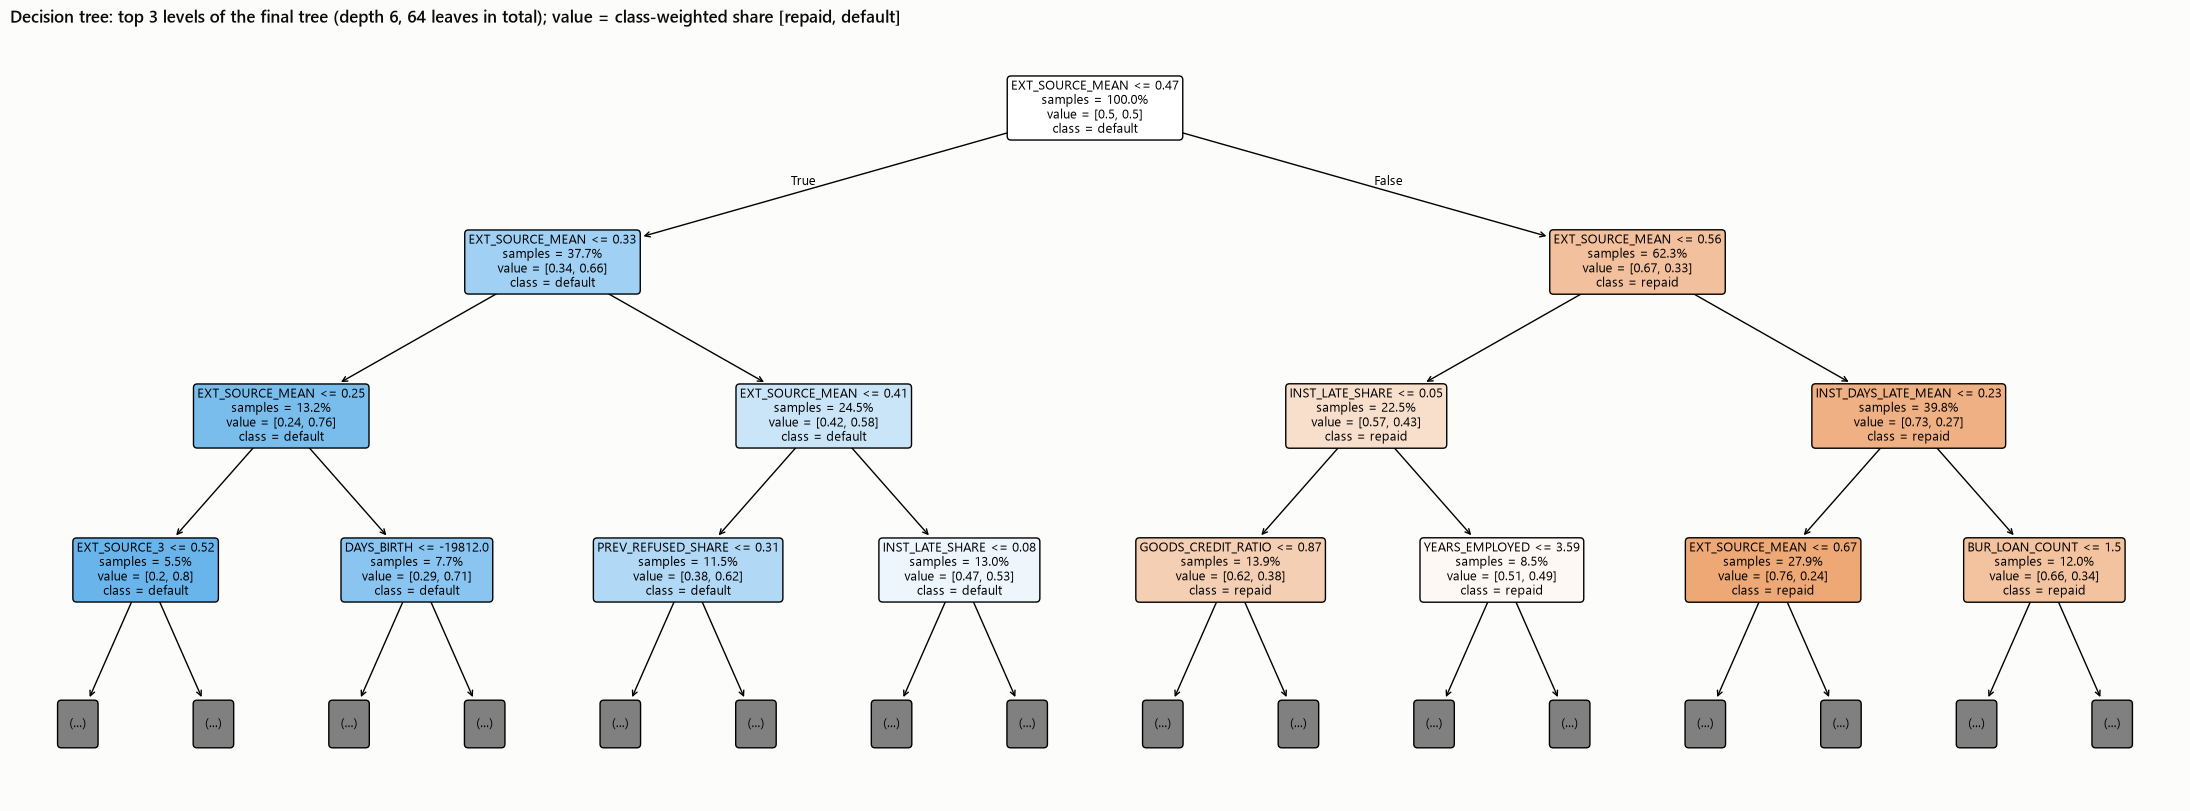

top 10 decision-tree inputs by impurity decrease:
EXT_SOURCE_MEAN               0.8111
GOODS_CREDIT_RATIO            0.0319
INST_LATE_SHARE               0.0253
INST_DAYS_LATE_MEAN           0.0201
BUR_LOAN_COUNT                0.0145
PREV_REFUSED_SHARE            0.0131
YEARS_EMPLOYED                0.0117
PREV_APP_CREDIT_RATIO_MEAN    0.0102
DAYS_EMPLOYED                 0.0076
EMPLOYED_TO_AGE               0.0069


In [9]:
input_names = [n.split("__", 1)[1] for n in dt.named_steps["pre"].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(28, 10))
plot_tree(tree, max_depth=3, feature_names=input_names, class_names=["repaid", "default"], filled=True,
          proportion=True, impurity=False, rounded=True, precision=2, fontsize=9, ax=ax)
ax.set_title(f"Decision tree: top 3 levels of the final tree (depth {tree.get_depth()}, {tree.get_n_leaves()} leaves "
             "in total); value = class-weighted share [repaid, default]", loc="left", fontsize=12,
             fontweight="semibold")
ax.set_xlabel("Each box: split rule, share of (weighted) training applicants reaching it, class-weighted mix; "
              "left branch = rule true")
ax.set_ylabel("Tree depth (root at the top)")
savefig(fig, "33_decision_tree_top3_levels.png")
plt.show()
importance = pd.Series(tree.feature_importances_, index=input_names).sort_values(ascending=False)
print("top 10 decision-tree inputs by impurity decrease:")
print(importance.head(10).round(4).to_string())

**Insight:** The grid search picked `max_depth` = 6 with `min_samples_leaf` = 200 (3-fold CV AUC 0.7229); its 5-fold CV AUC is
0.7266 ± 0.0022 and the final tree has 64 leaves. The tree is dominated by the external score: every split in the
top two levels uses `EXT_SOURCE_MEAN` (root at 0.47, then 0.33 and 0.56), and it accounts for 81.11% of the tree's
total impurity decrease (next: `GOODS_CREDIT_RATIO` 3.19%, `INST_LATE_SHARE` 2.53%). For applicants with a higher
score, the third level turns to repayment behaviour (`INST_LATE_SHARE` ≤ 0.05, `INST_DAYS_LATE_MEAN` ≤ 0.23).

## 6. Model 3 — Random forest

**How it works:** hundreds of decision trees, each grown on a random half of the training applicants
(`max_samples=0.5`, drawn with replacement) and choosing every split from a random subset of features
(`max_features`). The forest's score is the average of the trees' votes; averaging many decorrelated trees keeps
their low bias but cuts their variance.

**Preprocessing:** the same pipeline as the decision tree. **Imbalance:** `class_weight='balanced_subsample'`
re-weights defaulters inside every tree's bootstrap sample.

**Tuning (time-bounded):** random search over `n_estimators` {200, 400}, `max_depth` {12, 16, None},
`min_samples_leaf` {20, 50, 100} and `max_features` {'sqrt', 0.3} (36 combinations), each candidate scored by 3-fold
stratified CV AUC on train, bounded by `RF_TRIALS` candidates and a wall-clock budget. The best configuration is then
scored with the same 5-fold CV as the other models and refitted on the full training set.

In [10]:
RF_SPACE = {"n_estimators": [200, 400], "max_depth": [12, 16, None], "min_samples_leaf": [20, 50, 100],
            "max_features": ["sqrt", 0.3]}
RF_TRIALS, RF_BUDGET_MIN = 12, 35
rf_candidates = list(ParameterSampler(RF_SPACE, n_iter=RF_TRIALS, random_state=RANDOM_STATE))
rf_rows = []
t_search = time.time()
for i, params in enumerate(rf_candidates):
    if (time.time() - t_search) / 60 > RF_BUDGET_MIN:
        print(f"time budget of {RF_BUDGET_MIN} min reached after {i} trials")
        break
    res = cross_validate(make_rf_pipeline(NUM_COLS, CAT_COLS, **params), X_train, y_train, cv=cv3, scoring="roc_auc")
    seconds = res["fit_time"].sum() + res["score_time"].sum()
    rf_rows.append({"trial": i, **params, "cv3_auc_mean": res["test_score"].mean(),
                    "cv3_auc_std": res["test_score"].std(), "seconds": seconds})
    print(f"trial {i:>2}: 3-fold CV AUC {res['test_score'].mean():.4f} ± {res['test_score'].std():.4f} "
          f"({seconds:.0f}s)  {params}")
print(f"search finished: {len(rf_rows)} of {len(rf_candidates)} trials in {(time.time() - t_search) / 60:.1f} min")
rf_search = pd.DataFrame(rf_rows).sort_values("cv3_auc_mean", ascending=False)
rf_search.to_csv(REPORTS_DIR / "rf_search_results.csv", index=False)
display(rf_search.round(4))

trial  0: 3-fold CV AUC 0.7555 ± 0.0009 (159s)  {'n_estimators': 400, 'min_samples_leaf': 100, 'max_features': 0.3, 'max_depth': None}


trial  1: 3-fold CV AUC 0.7568 ± 0.0019 (58s)  {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 16}


trial  2: 3-fold CV AUC 0.7571 ± 0.0008 (36s)  {'n_estimators': 200, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': None}


trial  3: 3-fold CV AUC 0.7573 ± 0.0016 (98s)  {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': None}


trial  4: 3-fold CV AUC 0.7554 ± 0.0014 (35s)  {'n_estimators': 200, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 16}


trial  5: 3-fold CV AUC 0.7584 ± 0.0013 (180s)  {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': None}


... (3 outputs left out)

trial  9: 3-fold CV AUC 0.7557 ± 0.0012 (55s)  {'n_estimators': 400, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 16}


trial 10: 3-fold CV AUC 0.7558 ± 0.0014 (161s)  {'n_estimators': 400, 'min_samples_leaf': 50, 'max_features': 0.3, 'max_depth': 12}


trial 11: 3-fold CV AUC 0.7552 ± 0.0011 (87s)  {'n_estimators': 200, 'min_samples_leaf': 100, 'max_features': 0.3, 'max_depth': None}
search finished: 12 of 12 trials in 19.4 min


,trial,n_estimators,min_samples_leaf,max_features,max_depth,cv3_auc_mean,cv3_auc_std,seconds
5,5,400,20,0.3,NaN,0.7584,0.0013,179.9258
3,3,200,20,0.3,NaN,0.7573,0.0016,98.2284
6,6,400,50,0.3,16.0,0.7573,0.0012,166.8627
2,2,200,50,sqrt,NaN,0.7571,0.0008,35.8062
1,1,400,20,sqrt,16.0,0.7568,0.0019,58.3290
7,7,200,20,sqrt,16.0,0.7559,0.0019,36.7740
10,10,400,50,0.3,12.0,0.7558,0.0014,160.6787
9,9,400,100,sqrt,16.0,0.7557,0.0012,54.9140
0,0,400,100,0.3,NaN,0.7555,0.0009,158.6152
4,4,200,100,sqrt,16.0,0.7554,0.0014,34.8947


In [11]:
rf_best_params = rf_candidates[int(rf_search.iloc[0]["trial"])]
print("best random-forest parameters:", rf_best_params)
rf_cv = cross_validate_sklearn(make_rf_pipeline(NUM_COLS, CAT_COLS, **rf_best_params), X_train, y_train)
print(f"Random forest 5-fold CV AUC: {rf_cv['auc_mean']:.4f} ± {rf_cv['auc_std']:.4f} "
      f"(folds: {np.round(rf_cv['fold_aucs'], 4).tolist()}) [{rf_cv['seconds']:.0f}s]")
t0 = time.time()
rf = make_rf_pipeline(NUM_COLS, CAT_COLS, **rf_best_params).fit(X_train, y_train)
fit_seconds["Random forest"] = time.time() - t0
forest = rf.named_steps["model"]
print(f"final fit on full train: {fit_seconds['Random forest']:.0f}s; {forest.n_features_in_} model inputs; "
      f"mean nodes per tree {np.mean([t.tree_.node_count for t in forest.estimators_]):,.0f}; "
      f"mean tree depth {np.mean([t.get_depth() for t in forest.estimators_]):.1f}")

best random-forest parameters: {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': None}


Random forest 5-fold CV AUC: 0.7592 ± 0.0022 (folds: [0.7585, 0.7629, 0.759, 0.7561, 0.7593]) [377s]


final fit on full train: 100s; 234 model inputs; mean nodes per tree 4,845; mean tree depth 30.2


**Insight:** All 12 sampled configurations finished within the budget (19.4 min). Their 3-fold CV AUCs lie in a narrow band
(0.7552–0.7584), so the forest is not very sensitive to these settings; the best uses 400 fully grown trees
(`max_depth=None`), `min_samples_leaf` = 20 and `max_features` = 0.3. Its 5-fold CV AUC is 0.7592 ± 0.0022, far above
the single tree (0.7266), but the trees are large (mean depth 30.2, 4,845 nodes each), the final fit takes 100 s and
the saved model is 57.0 MB.

## 7. Cross-validation summary and training time (training set only)

In [12]:
cv_all = {"Logistic regression": lr_cv, "Decision tree": dt_cv, "Random forest": rf_cv, "XGBoost": xgb_cv,
          "LightGBM": lgbm_cv}
cv_summary = pd.DataFrame({
    name: {"CV_AUC_mean": cv_all[name]["auc_mean"], "CV_AUC_std": cv_all[name]["auc_std"],
           **{f"fold_{k + 1}": auc for k, auc in enumerate(cv_all[name]["fold_aucs"])},
           "train_seconds": fit_seconds[name]}
    for name in MODEL_ORDER}).T
cv_summary.index.name = "model"
display(cv_summary.round(4))
print("training time = one fit of the final model on the full training set (boosting models train on 90% and use "
      "10% for early stopping; random forest, XGBoost and LightGBM use all CPU cores).")

,CV_AUC_mean,CV_AUC_std,fold_1,fold_2,fold_3,fold_4,fold_5,train_seconds
model,,,,,,,,
Logistic regression,0.7600,0.0013,0.7593,0.7619,0.7610,0.7586,0.7591,18.6767
Decision tree,0.7266,0.0022,0.7260,0.7294,0.7236,0.7252,0.7288,16.7525
Random forest,0.7592,0.0022,0.7585,0.7629,0.7590,0.7561,0.7593,99.7787
XGBoost,0.7698,0.0017,0.7692,0.7691,0.7729,0.7679,0.7700,19.3461
LightGBM,0.7758,0.0015,0.7745,0.7763,0.7784,0.7742,0.7757,17.9060


training time = one fit of the final model on the full training set (boosting models train on 90% and use 10% for early stopping; random forest, XGBoost and LightGBM use all CPU cores).


**Insight:** Cross-validated ranking on the training set: LightGBM 0.7758 ± 0.0015 > XGBoost 0.7698 ± 0.0017 > logistic regression
0.7600 ± 0.0013 > random forest 0.7592 ± 0.0022 > decision tree 0.7266 ± 0.0022. Fold-to-fold spread is at most
0.0022, so the order is stable, except that logistic regression and random forest differ by only 0.0008. The final
fits take 16.8 s (decision tree) to 19.3 s (XGBoost) for four models; the random forest needs 99.8 s.

## 8. Holdout evaluation (run once): the metrics and why they were chosen

The holdout applicants are scored **once per model** below; nothing that follows changes a model.

- **AUC-ROC** and **Gini** (= 2·AUC − 1, the form credit-risk teams report): the probability that a randomly chosen
  defaulter gets a higher score than a randomly chosen good applicant. Threshold-free and unaffected by the class
  ratio, it measures *ranking*, which any approve/reject cut-off relies on.
- **PR-AUC** (average precision): precision against recall for the default class. Its random baseline equals the
  default rate, so it shows how hard the rare class is to find; it is the stricter view when positives are rare.
- **KS:** the largest gap between the cumulative score distributions of defaulters and good applicants, a classic
  scorecard statistic.
- **Recall** (share of defaulters caught), **precision** (share of rejected applicants who really default) and
  **F1** (their harmonic mean), all for the default class. Missed defaulters are the expensive error, so recall and F1
  say far more than accuracy.
- **Accuracy** is reported to show why it misleads: with about 8% defaults, predicting "repaid" for everyone is about
  92% accurate (computed below) while catching no defaulter.
- **Log loss** judges the scores as probabilities. Class weighting (`class_weight` / `scale_pos_weight`) deliberately
  pushes every model's scores upwards so that defaulters are not ignored; the scores therefore rank well but are
  **higher than real default probabilities**, which inflates log loss. It is reported for completeness, not used to
  choose a model.
- **Two thresholds:** 0.5 (the conventional default) and each model's cost-optimal threshold (section 9).

In [13]:
models = {"Logistic regression": logreg, "Decision tree": dt, "Random forest": rf, "XGBoost": xgb, "LightGBM": lgbm}
holdout_probs = {name: models[name].predict_proba(X_holdout)[:, 1] for name in MODEL_ORDER}

rows = []
for name, prob in holdout_probs.items():
    rows.append({"model": name, "CV_AUC_mean": cv_all[name]["auc_mean"], "CV_AUC_std": cv_all[name]["auc_std"],
                 **evaluate(y_holdout, prob, threshold=0.5)})
metrics_table = pd.DataFrame(rows).set_index("model")
display(metrics_table.round(4))

# Leakage guard required by the project rules.
too_good = metrics_table[metrics_table["AUC"] > 0.85]
if len(too_good):
    raise RuntimeError(f"Holdout AUC above 0.85 for {too_good.index.tolist()} - investigate leakage before continuing")
print(f"leakage guard passed: max holdout AUC = {metrics_table['AUC'].max():.4f} (<= 0.85)")

baseline_acc = 1 - y_holdout.mean()
print(f"accuracy of predicting 'repaid' for everyone on the holdout: {baseline_acc:.4%}")

,CV_AUC_mean,CV_AUC_std,AUC,Gini,PR_AUC,KS,Precision@0.5,Recall@0.5,F1@0.5,Accuracy@0.5,TN,FP,FN,TP
model,,,,,,,,,,,,,,
Logistic regression,0.7600,0.0013,0.7641,0.5281,0.2482,0.3989,0.1694,0.6971,0.2726,0.6997,39571,16966,1504,3461
Decision tree,0.7266,0.0022,0.7269,0.4539,0.1988,0.3346,0.1462,0.6870,0.2410,0.6507,36611,19926,1554,3411
Random forest,0.7592,0.0022,0.7618,0.5236,0.2495,0.3987,0.2753,0.3347,0.3021,0.8752,52162,4375,3303,1662
XGBoost,0.7698,0.0017,0.7744,0.5489,0.2693,0.4079,0.1931,0.6377,0.2964,0.7556,43304,13233,1799,3166
LightGBM,0.7758,0.0015,0.7819,0.5638,0.2818,0.4237,0.1896,0.6733,0.2959,0.7414,42252,14285,1622,3343


leakage guard passed: max holdout AUC = 0.7819 (<= 0.85)
accuracy of predicting 'repaid' for everyone on the holdout: 91.9271%


**Insight:** The holdout confirms the CV ranking: AUC 0.7819 (LightGBM), 0.7744 (XGBoost), 0.7641 (logistic regression), 0.7618
(random forest) and 0.7269 (decision tree); LightGBM also has the highest Gini (0.5638), PR-AUC (0.2818) and KS
(0.4237). At threshold 0.5 accuracy ranges from 65.07% (decision tree) to 87.52% (random forest), and every model is
less accurate than approving everyone (91.93%). The random forest's high accuracy at 0.5 does not mean it is better:
it flags far fewer applicants and catches only 33.47% of defaulters, against 69.71% for logistic regression.

## 9. Cost-optimal thresholds and the final metrics table

Each model's threshold minimises total cost on **its own training out-of-fold predictions** (thresholds 0.01–0.99,
`src/cost.py`): approving a defaulter costs 0.60 × `AMT_CREDIT` (loss given default), rejecting a good applicant
costs 0.15 × `AMT_CREDIT` (lost margin). These costs are assumptions. The chosen threshold is then applied once to
the holdout. An applicant is rejected when the score is at or above the threshold.

`reports/metrics_table_final.csv` has one row per model per threshold type with all nine metrics, the confusion
counts, the decision outcome (approval rate, default rate among approved, total cost and saving vs approving
everyone), CV AUC and training time.

In [14]:
credit_train, credit_holdout = train["AMT_CREDIT"].to_numpy(), holdout["AMT_CREDIT"].to_numpy()
opt_thresholds = {name: optimal_threshold(threshold_sweep(y_train, cv_all[name]["oof"], credit_train))
                  for name in MODEL_ORDER}
print("cost-optimal thresholds chosen on train OOF predictions:", opt_thresholds)
base_cost = approve_all_cost(y_holdout, credit_holdout)

rows = []
for name in MODEL_ORDER:
    prob = holdout_probs[name]
    for t_type, t in [("0.5", 0.5), ("cost-optimal", opt_thresholds[name])]:
        s = decision_summary(y_holdout, prob, credit_holdout, t)
        rows.append({"model": name, "threshold_type": t_type, "threshold": t, **metric_row(y_holdout, prob, t),
                     "approval_rate": s["approval_rate"], "default_rate_approved": s["default_rate_approved"],
                     "total_cost": s["total_cost"], "saving_vs_approve_all": 1 - s["total_cost"] / base_cost,
                     "CV_AUC_mean": cv_all[name]["auc_mean"], "CV_AUC_std": cv_all[name]["auc_std"],
                     "train_seconds": fit_seconds[name]})
final_table = pd.DataFrame(rows)
for t_type in ["0.5", "cost-optimal"]:
    print(f"threshold type: {t_type}")
    display(final_table[final_table["threshold_type"] == t_type].set_index("model")[["threshold"] + METRICS]
            .round(4))
display(final_table.set_index(["model", "threshold_type"])[
    ["threshold", "TN", "FP", "FN", "TP", "approval_rate", "default_rate_approved", "total_cost",
     "saving_vs_approve_all"]].style.format(
    {"threshold": "{:.2f}", "approval_rate": "{:.2%}", "default_rate_approved": "{:.2%}", "total_cost": "{:,.0f}",
     "saving_vs_approve_all": "{:+.2%}"}))
print(f"holdout cost of approving everyone: {base_cost:,.0f}")
opt = final_table[final_table["threshold_type"] == "cost-optimal"].set_index("model")
best_by_metric = {m: (opt[m].idxmin() if m == "LogLoss" else opt[m].idxmax()) for m in METRICS}
print("best model per metric at the cost-optimal thresholds:", best_by_metric)

cost-optimal thresholds chosen on train OOF predictions: {'Logistic regression': 0.74, 'Decision tree': 0.76, 'Random forest': 0.52, 'XGBoost': 0.7, 'LightGBM': 0.7}


threshold type: 0.5


,threshold,Accuracy,Precision,Recall,F1,LogLoss,AUC,Gini,PR_AUC,KS
model,,,,,,,,,,
Logistic regression,0.5,0.6997,0.1694,0.6971,0.2726,0.5778,0.7641,0.5281,0.2482,0.3989
Decision tree,0.5,0.6507,0.1462,0.6870,0.2410,0.6032,0.7269,0.4539,0.1988,0.3346
Random forest,0.5,0.8752,0.2753,0.3347,0.3021,0.3601,0.7618,0.5236,0.2495,0.3987
XGBoost,0.5,0.7556,0.1931,0.6377,0.2964,0.5045,0.7744,0.5489,0.2693,0.4079
LightGBM,0.5,0.7414,0.1896,0.6733,0.2959,0.5194,0.7819,0.5638,0.2818,0.4237


threshold type: cost-optimal


,threshold,Accuracy,Precision,Recall,F1,LogLoss,AUC,Gini,PR_AUC,KS
model,,,,,,,,,,
Logistic regression,0.74,0.8832,0.2894,0.3072,0.2980,0.5778,0.7641,0.5281,0.2482,0.3989
Decision tree,0.76,0.8950,0.2825,0.1950,0.2307,0.6032,0.7269,0.4539,0.1988,0.3346
Random forest,0.52,0.8828,0.2877,0.3065,0.2968,0.3601,0.7618,0.5236,0.2495,0.3987
XGBoost,0.70,0.8805,0.2892,0.3293,0.3079,0.5045,0.7744,0.5489,0.2693,0.4079
LightGBM,0.70,0.8750,0.2903,0.3797,0.3290,0.5194,0.7819,0.5638,0.2818,0.4237


holdout cost of approving everyone: 1,665,214,629
best model per metric at the cost-optimal thresholds: {'Accuracy': 'Decision tree', 'Precision': 'LightGBM', 'Recall': 'LightGBM', 'F1': 'LightGBM', 'LogLoss': 'Random forest', 'AUC': 'LightGBM', 'Gini': 'LightGBM', 'PR_AUC': 'LightGBM', 'KS': 'LightGBM'}


**Insight:** Cost-optimal thresholds chosen on the training OOF predictions: 0.74 (logistic regression), 0.76 (decision tree),
0.52 (random forest), 0.70 (XGBoost) and 0.70 (LightGBM, the same as notebook 04). At these thresholds LightGBM is
best on precision (0.2903), recall (0.3797) and F1 (0.3290) and gives the largest saving vs approving everyone
(14.04%; approval 89.44%, default rate among approved 5.60%), ahead of XGBoost (11.65%), random forest (10.82%),
logistic regression (10.74%) and the decision tree (6.72%). The decision tree has the highest accuracy (89.50%) only
because it rejects the fewest applicants and catches just 19.50% of defaulters. At 0.5, four of the five models cost
more than approving everyone (from −3.91% for XGBoost to −32.33% for the decision tree); only the random forest,
whose optimum (0.52) is close to 0.5, saves money there (10.61%).

### Confusion matrices

saved reports/figures/20_confusion_matrices.png


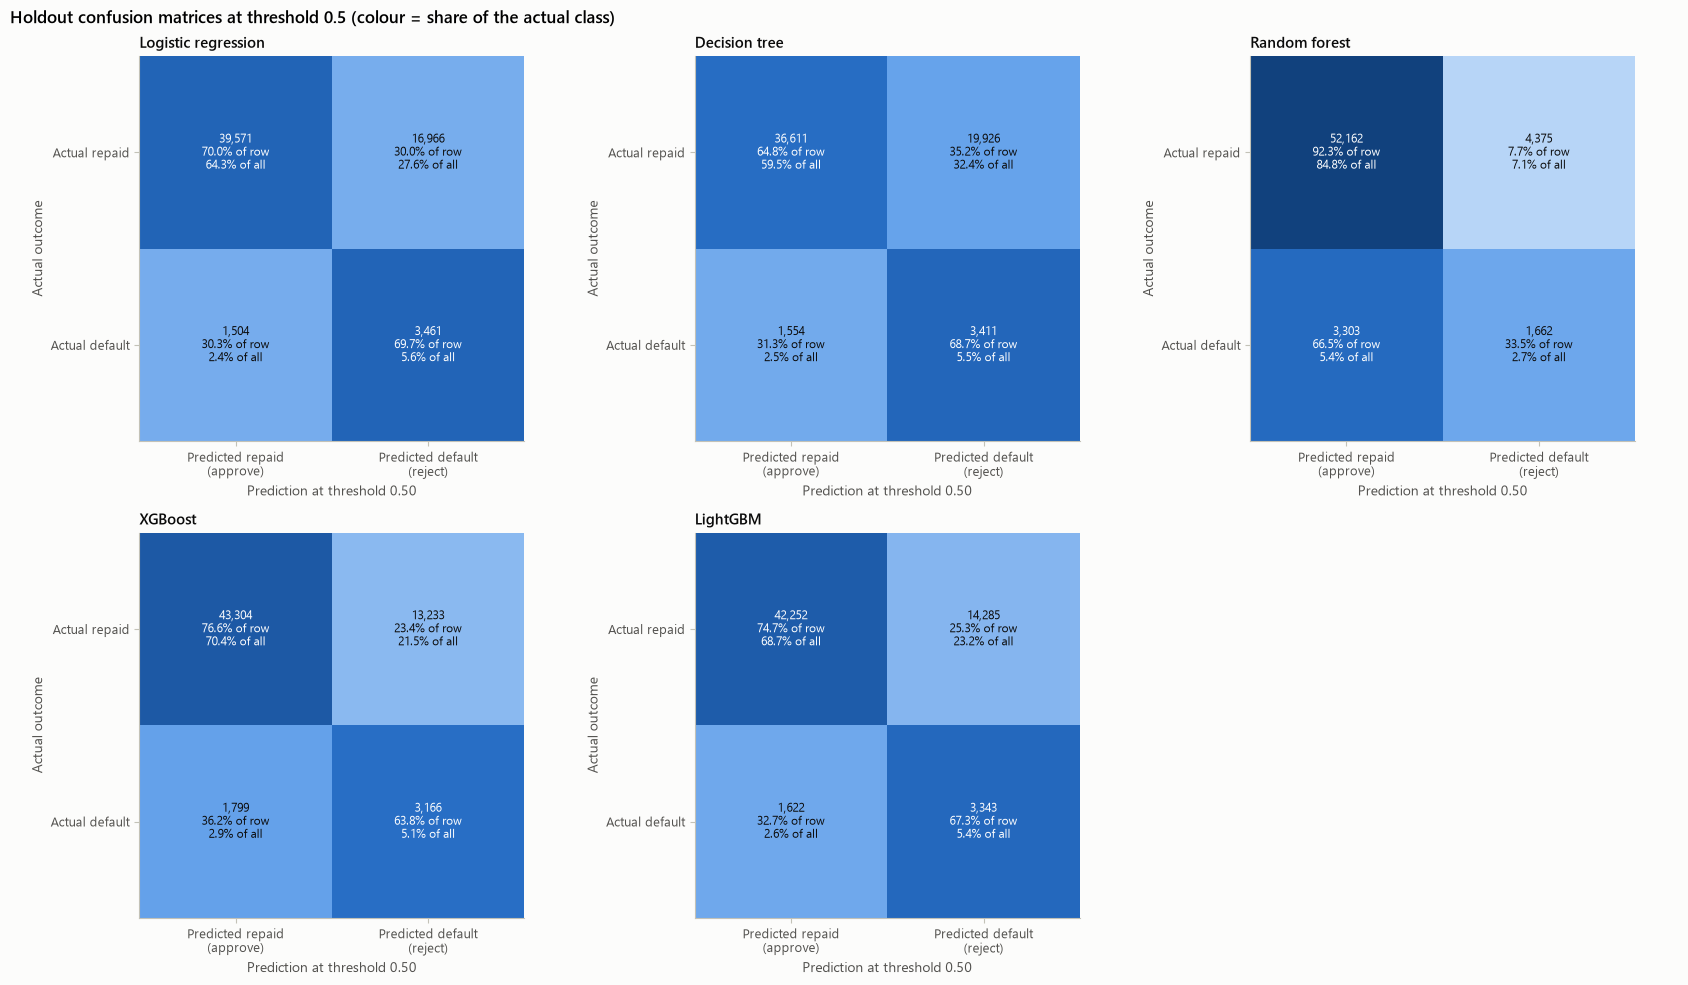

saved reports/figures/34_confusion_matrices_cost_optimal.png


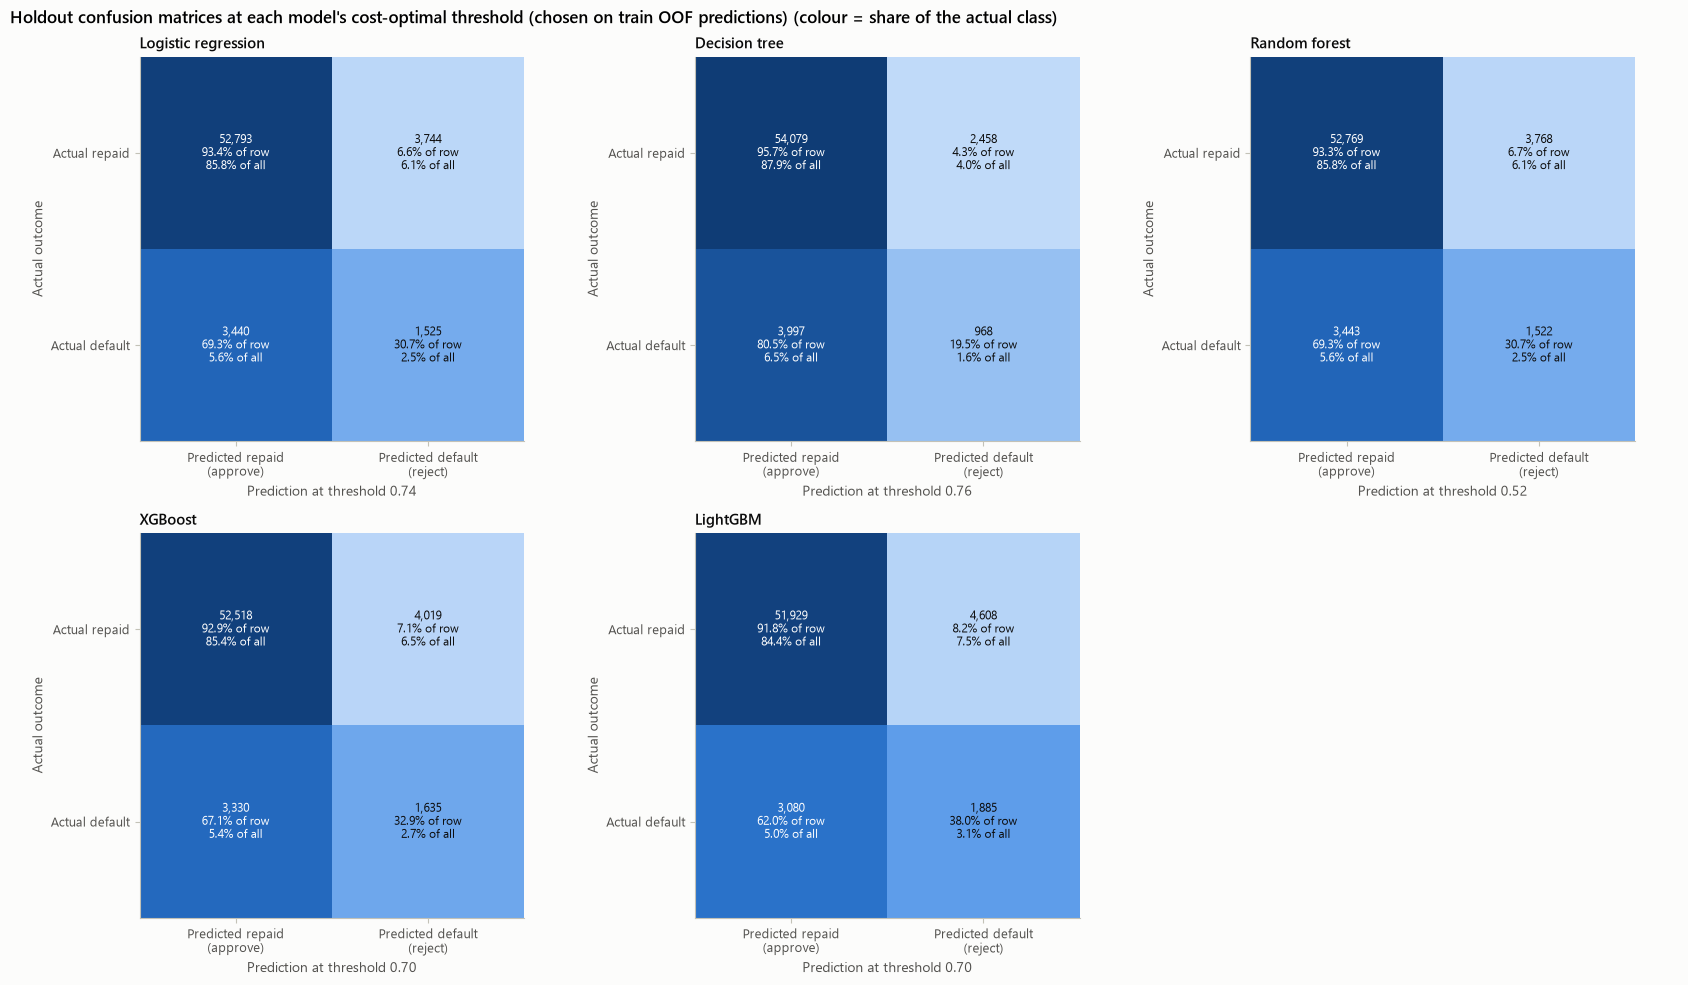

In [15]:
for t_type, fname, title in [
        ("0.5", "20_confusion_matrices.png", "Holdout confusion matrices at threshold 0.5"),
        ("cost-optimal", "34_confusion_matrices_cost_optimal.png",
         "Holdout confusion matrices at each model's cost-optimal threshold (chosen on train OOF predictions)")]:
    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    for ax, name in zip(axes.ravel(), MODEL_ORDER):
        r = final_table[(final_table["model"] == name) & (final_table["threshold_type"] == t_type)].iloc[0]
        plot_confusion(ax, r["TN"], r["FP"], r["FN"], r["TP"], name, f"Prediction at threshold {r['threshold']:.2f}")
    axes.ravel()[-1].axis("off")
    fig.suptitle(f"{title} (colour = share of the actual class)", x=0.01, ha="left", fontweight="semibold")
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()

**Insight:** At the cost-optimal thresholds LightGBM catches 1,885 of the 4,965 holdout defaulters (38.0%) while rejecting 4,608
good applicants (8.2% of them); XGBoost catches 1,635, logistic regression 1,525, the random forest 1,522 and the
decision tree only 968 (19.5%). At 0.5 (`20_confusion_matrices.png`) the class-weighted models flag many more
applicants: the decision tree rejects 19,926 good applicants and logistic regression 16,966.

### ROC and precision-recall curves, LightGBM feature importance, score calibration

saved reports/figures/16_roc_curves.png


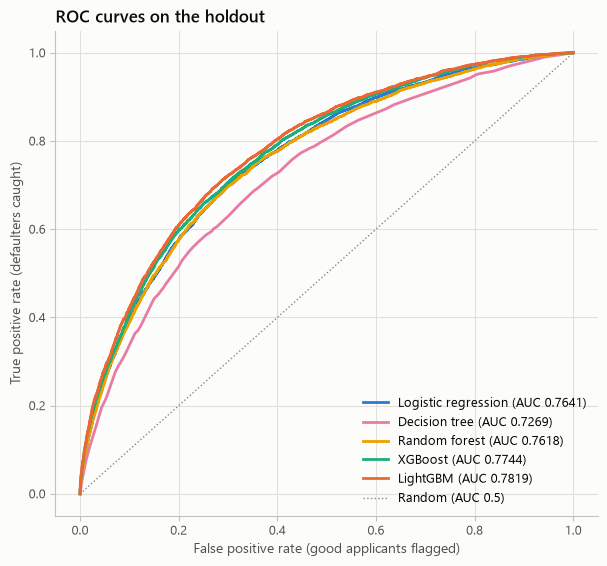

In [16]:
fig, ax = plt.subplots(figsize=(7, 6.3))
for name in MODEL_ORDER:
    fpr, tpr, _ = roc_curve(y_holdout, holdout_probs[name])
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], label=f"{name} (AUC {metrics_table.loc[name, 'AUC']:.4f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1, label="Random (AUC 0.5)")
ax.set_title("ROC curves on the holdout", loc="left")
ax.set_xlabel("False positive rate (good applicants flagged)")
ax.set_ylabel("True positive rate (defaulters caught)")
ax.legend(loc="lower right")
savefig(fig, "16_roc_curves.png")
plt.show()

**Insight:** LightGBM's ROC curve lies on or above the others over almost the whole range (AUC 0.7819), followed closely by
XGBoost (0.7744). Logistic regression (0.7641) and the random forest (0.7618) nearly overlap. The decision tree's
curve is clearly lower (0.7269) and made of straight segments, because its 64 leaves give only 64 distinct scores.

saved reports/figures/17_pr_curves.png


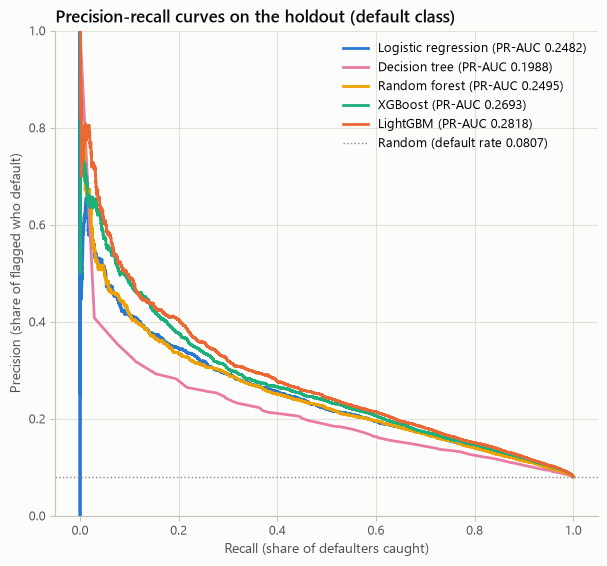

In [17]:
fig, ax = plt.subplots(figsize=(7, 6.3))
for name in MODEL_ORDER:
    precision, recall, _ = precision_recall_curve(y_holdout, holdout_probs[name])
    ax.plot(recall, precision, color=MODEL_COLORS[name],
            label=f"{name} (PR-AUC {metrics_table.loc[name, 'PR_AUC']:.4f})")
ax.axhline(y_holdout.mean(), color=MUTED, linestyle=":", linewidth=1,
           label=f"Random (default rate {y_holdout.mean():.4f})")
ax.set_title("Precision-recall curves on the holdout (default class)", loc="left")
ax.set_xlabel("Recall (share of defaulters caught)")
ax.set_ylabel("Precision (share of flagged who default)")
ax.set_ylim(0, 1)
ax.legend(loc="upper right")
savefig(fig, "17_pr_curves.png")
plt.show()

**Insight:** On the stricter precision-recall view (random baseline = default rate 0.0807), LightGBM again leads (PR-AUC 0.2818),
then XGBoost (0.2693), the random forest (0.2495), logistic regression (0.2482) and the decision tree (0.1988). The
random forest edges past logistic regression on PR-AUC despite its lower AUC, i.e. it is slightly better at the
riskiest end of the ranking.

top 25 features account for 69.08% of total gain; features with zero gain: 13 of 161


,share_of_gain
EXT_SOURCE_MEAN,0.2219
ORGANIZATION_TYPE,0.0606
EXT_SOURCE_3,0.0462
CREDIT_TERM,0.0439
EXT_SOURCE_2,0.0361
EXT_SOURCE_1,0.0227
OCCUPATION_TYPE,0.0216
GOODS_CREDIT_RATIO,0.0207
INST_LATE_SHARE,0.0197
PREV_APP_CREDIT_RATIO_MEAN,0.0177


saved reports/figures/18_lgbm_feature_importance_gain.png


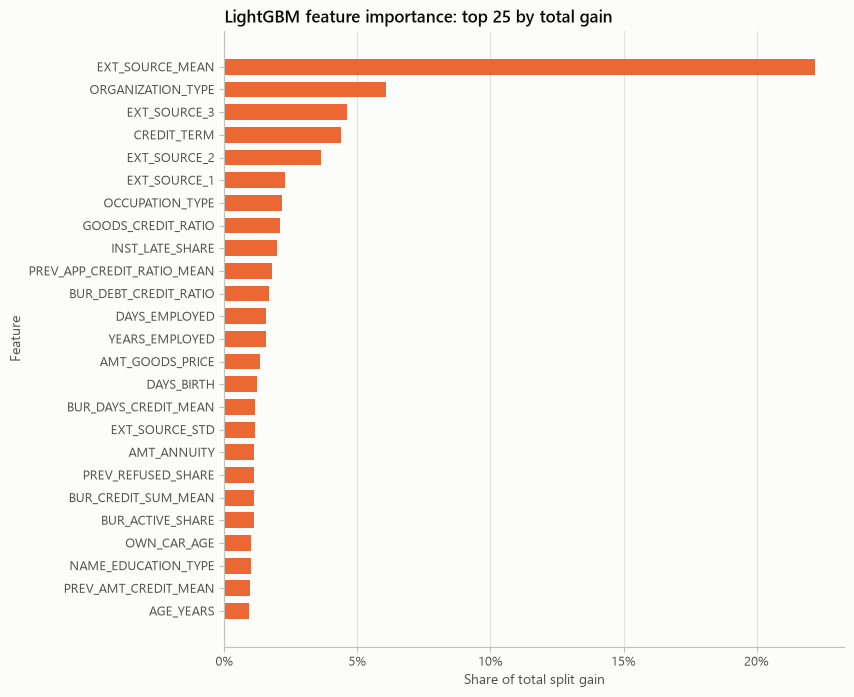

In [18]:
gain = pd.Series(lgbm.booster_.feature_importance(importance_type="gain"), index=lgbm.booster_.feature_name())
gain_share = (gain / gain.sum()).sort_values(ascending=False)
top25 = gain_share.head(25)
print(f"top 25 features account for {top25.sum():.2%} of total gain; "
      f"features with zero gain: {int((gain == 0).sum())} of {len(gain)}")
display(top25.to_frame("share_of_gain").round(4))

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top25.index, top25.values, color=SERIES[1], height=0.7)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("LightGBM feature importance: top 25 by total gain", loc="left")
ax.set_xlabel("Share of total split gain")
ax.set_ylabel("Feature")
ax.grid(axis="y", visible=False)
savefig(fig, "18_lgbm_feature_importance_gain.png")
plt.show()

**Insight:** `EXT_SOURCE_MEAN` alone accounts for 22.19% of the total split gain. Next come `ORGANIZATION_TYPE`
(6.06%), `EXT_SOURCE_3` (4.62%) and the engineered `CREDIT_TERM` (4.39%). Engineered features from all three side
tables reach the top 25, for example `INST_LATE_SHARE` (1.97%), `PREV_APP_CREDIT_RATIO_MEAN` (1.77%) and
`BUR_DEBT_CREDIT_RATIO` (1.67%). The top 25 features carry 69.08% of the total gain, and 13 of the 161 features are
never used for a split.

saved reports/figures/19_calibration_curves.png


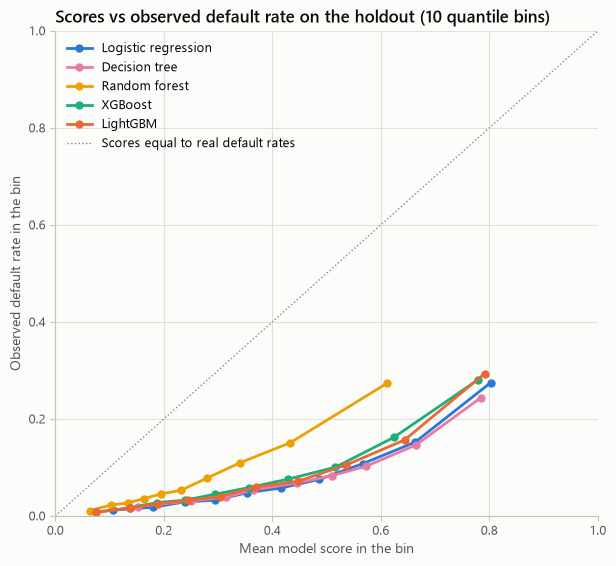

,mean_score,actual_default_rate,top_decile_mean_score,top_decile_actual_rate
model,,,,
Logistic regression,0.4109,0.0807,0.8029,0.2751
Decision tree,0.4273,0.0807,0.7838,0.2433
Random forest,0.2555,0.0807,0.6115,0.2736
XGBoost,0.3638,0.0807,0.7790,0.2806
LightGBM,0.3737,0.0807,0.7916,0.2936


In [19]:
fig, ax = plt.subplots(figsize=(7, 6.3))
calib_rows = []
for name in MODEL_ORDER:
    prob = holdout_probs[name]
    frac_pos, mean_pred = calibration_curve(y_holdout, prob, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", markersize=5, color=MODEL_COLORS[name], label=name)
    calib_rows.append({"model": name, "mean_score": prob.mean(), "actual_default_rate": y_holdout.mean(),
                       "top_decile_mean_score": mean_pred[-1], "top_decile_actual_rate": frac_pos[-1]})
ax.plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1, label="Scores equal to real default rates")
ax.set_title("Scores vs observed default rate on the holdout (10 quantile bins)", loc="left")
ax.set_xlabel("Mean model score in the bin")
ax.set_ylabel("Observed default rate in the bin")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left")
savefig(fig, "19_calibration_curves.png")
plt.show()
display(pd.DataFrame(calib_rows).set_index("model").round(4))

**Insight:** None of the models outputs real probabilities. Mean scores on the holdout are 0.4109 (logistic regression), 0.4273
(decision tree), 0.2555 (random forest), 0.3638 (XGBoost) and 0.3737 (LightGBM), against an actual default rate of
0.0807; even the top-score decile defaults at only 24.33%–29.36%. This is the intended effect of class weighting,
and it is why log loss is inflated: the random forest, whose scores are least inflated, has the lowest log loss
(0.3601), and the decision tree the highest (0.6032), although neither ranks best.

## 10. Every metric side by side

saved reports/figures/35_metrics_grouped_bars.png


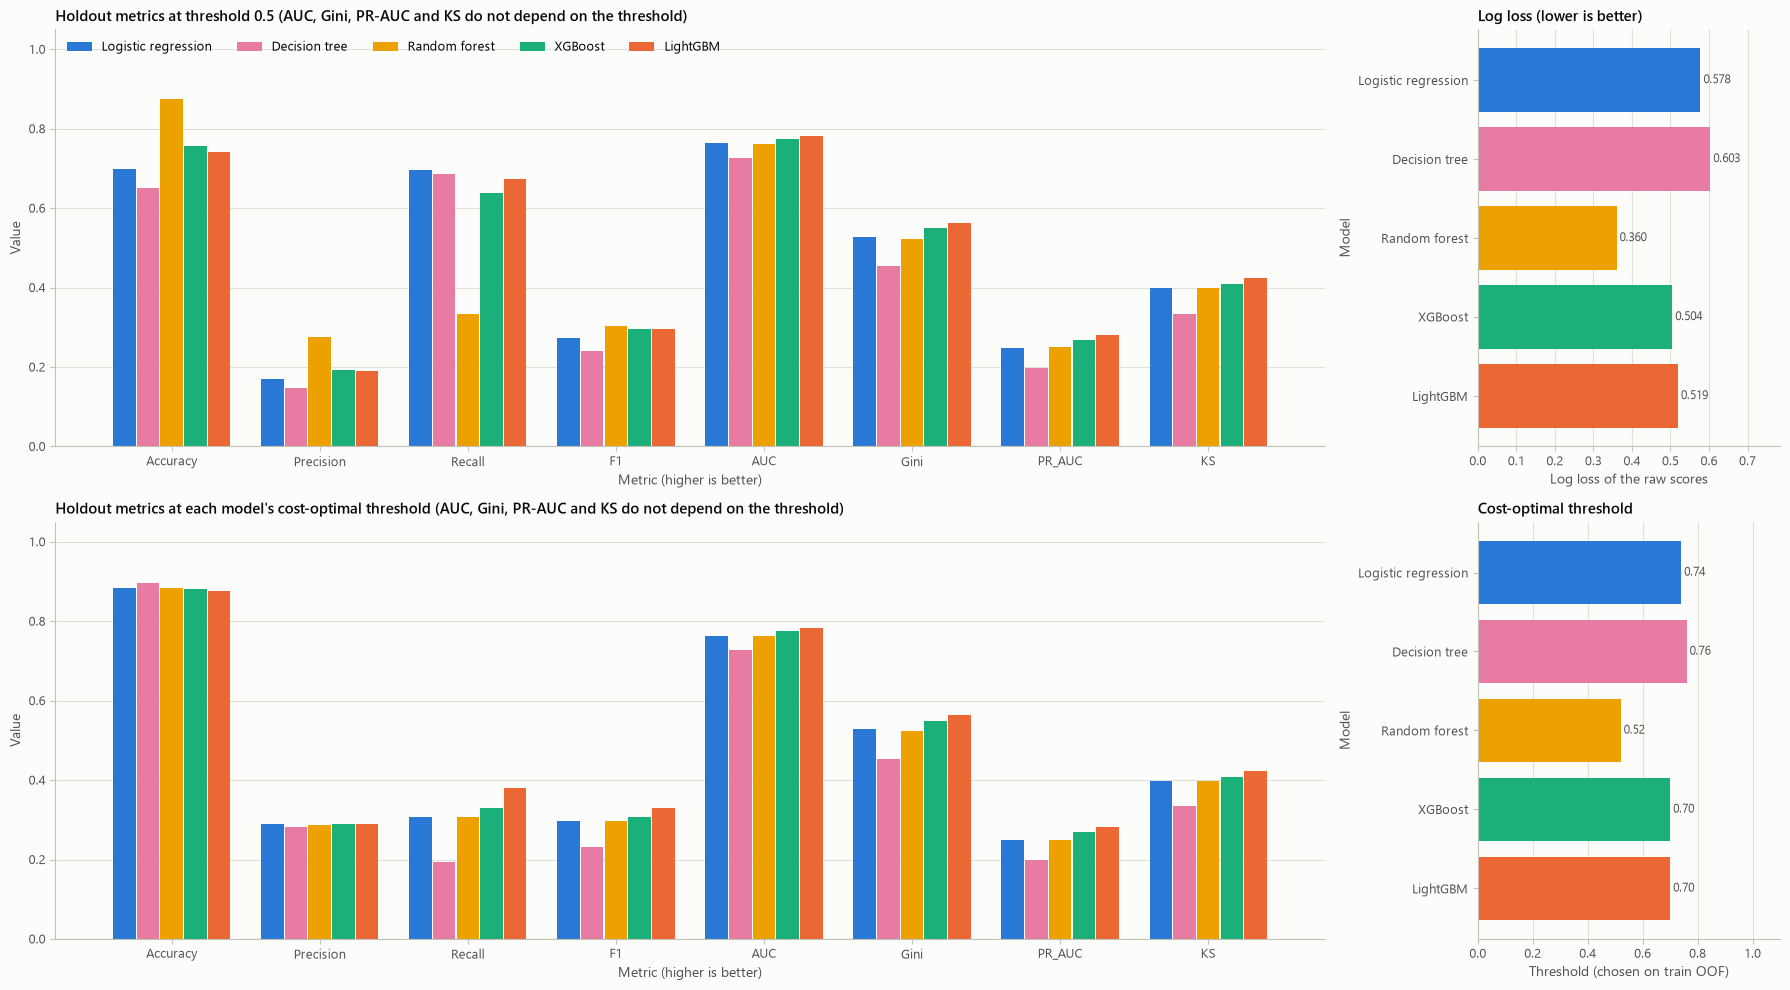

In [20]:
BAR_METRICS = ["Accuracy", "Precision", "Recall", "F1", "AUC", "Gini", "PR_AUC", "KS"]
fig, axes = plt.subplots(2, 2, figsize=(18, 10), gridspec_kw={"width_ratios": [4.2, 1]})
width = 0.16
for row, t_type in enumerate(["0.5", "cost-optimal"]):
    sub = final_table[final_table["threshold_type"] == t_type].set_index("model")
    ax = axes[row, 0]
    x = np.arange(len(BAR_METRICS))
    for k, name in enumerate(MODEL_ORDER):
        vals = sub.loc[name, BAR_METRICS].to_numpy(dtype=float)
        ax.bar(x + (k - 2) * width, vals, width=width * 0.95, color=MODEL_COLORS[name], label=name)
    ax.set_xticks(x, BAR_METRICS)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Holdout metrics at {'threshold 0.5' if t_type == '0.5' else 'each model' + chr(39) + 's cost-optimal threshold'} "
                 "(AUC, Gini, PR-AUC and KS do not depend on the threshold)", loc="left", fontsize=11)
    ax.set_xlabel("Metric (higher is better)")
    ax.set_ylabel("Value")
    ax.grid(axis="x", visible=False)
    if row == 0:
        ax.legend(loc="upper left", ncol=5, fontsize=9)
opt = final_table[final_table["threshold_type"] == "cost-optimal"].set_index("model").loc[MODEL_ORDER]
axes[0, 1].barh(MODEL_ORDER[::-1], opt["LogLoss"][::-1], color=[MODEL_COLORS[n] for n in MODEL_ORDER[::-1]])
for yp, v in enumerate(opt["LogLoss"][::-1]):
    axes[0, 1].text(v, yp, f" {v:.3f}", va="center", fontsize=8.5, color=INK_2)
axes[0, 1].set_title("Log loss (lower is better)", loc="left", fontsize=11)
axes[0, 1].set_xlabel("Log loss of the raw scores")
axes[0, 1].set_xlim(0, opt["LogLoss"].max() * 1.3)
axes[1, 1].barh(MODEL_ORDER[::-1], opt["threshold"][::-1], color=[MODEL_COLORS[n] for n in MODEL_ORDER[::-1]])
for yp, v in enumerate(opt["threshold"][::-1]):
    axes[1, 1].text(v, yp, f" {v:.2f}", va="center", fontsize=8.5, color=INK_2)
axes[1, 1].set_title("Cost-optimal threshold", loc="left", fontsize=11)
axes[1, 1].set_xlabel("Threshold (chosen on train OOF)")
axes[1, 1].set_xlim(0, 1.1)
for ax in axes[:, 1]:
    ax.set_ylabel("Model")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "35_metrics_grouped_bars.png")
plt.show()

**Insight:** At threshold 0.5 the threshold-based metrics swing widely (accuracy 0.6507–0.8752, recall 0.3347–0.6971), mainly
because each model flags a different number of applicants at the same nominal cut-off. At the cost-optimal thresholds
accuracy converges (0.8750–0.8950) and LightGBM leads on precision, recall and F1 as well as on all threshold-free
metrics; the cost-optimal thresholds themselves range from 0.52 (random forest) to 0.76 (decision tree).

saved reports/figures/36_metrics_heatmap.png


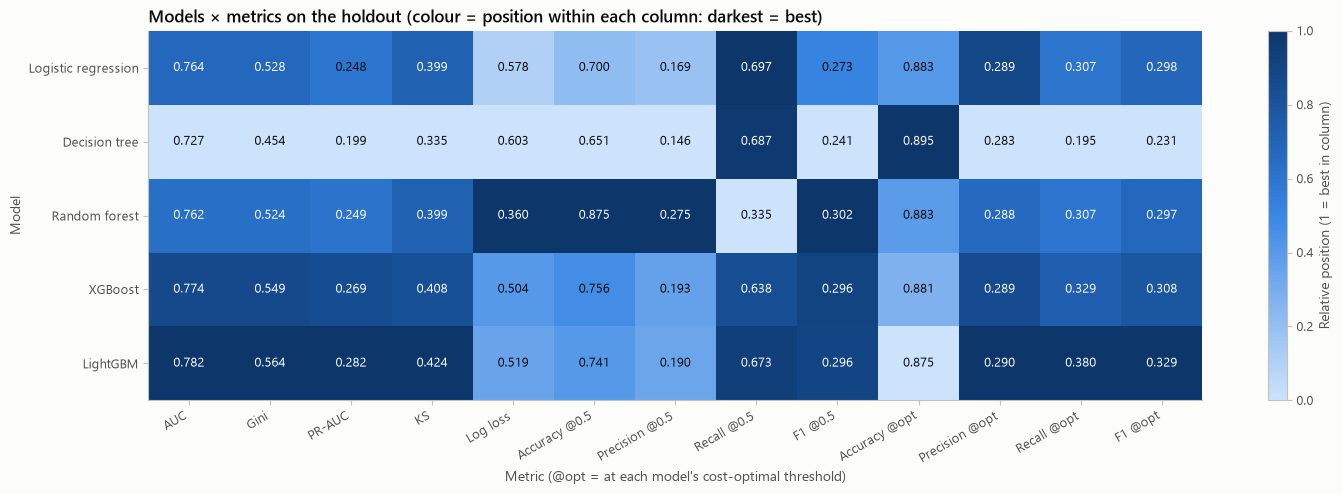

In [21]:
heat_cols = {"AUC": "AUC", "Gini": "Gini", "PR_AUC": "PR-AUC", "KS": "KS", "LogLoss": "Log loss"}
wide = final_table.pivot(index="model", columns="threshold_type", values=["Accuracy", "Precision", "Recall", "F1"])
heat = pd.concat([opt[list(heat_cols)].rename(columns=heat_cols)] + [
    wide[(m, t)].rename(f"{m} @{'0.5' if t == '0.5' else 'opt'}") for t in ["0.5", "cost-optimal"]
    for m in ["Accuracy", "Precision", "Recall", "F1"]], axis=1).loc[MODEL_ORDER]
lower_better = {"Log loss"}
norm = heat.apply(lambda c: (c.max() - c) / (c.max() - c.min()) if c.name in lower_better
                  else (c - c.min()) / (c.max() - c.min()))
fig, ax = plt.subplots(figsize=(17, 4.8))
im = ax.imshow(norm.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(heat.to_numpy()):
    ax.text(c, r, f"{v:.3f}", ha="center", va="center", fontsize=9,
            color="white" if norm.to_numpy()[r, c] > 0.6 else "#0b0b0b")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=30, ha="right")
ax.set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER)
ax.set_xlabel("Metric (@opt = at each model's cost-optimal threshold)")
ax.set_ylabel("Model")
ax.set_title("Models × metrics on the holdout (colour = position within each column: darkest = best)", loc="left")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Relative position (1 = best in column)")
savefig(fig, "36_metrics_heatmap.png")
plt.show()

**Insight:** LightGBM is the darkest cell in AUC, Gini, PR-AUC, KS and in precision, recall and F1 at the cost-optimal threshold.
The only columns it does not win are log loss (random forest, 0.3601), accuracy at the cost-optimal threshold
(decision tree, 0.8950), and accuracy, precision and F1 at 0.5 (random forest) and recall at 0.5 (logistic
regression, 0.6971): all of them depend on how many applicants a model happens to flag, not on how well it ranks.

## 11. How accuracy, precision, recall and F1 change with the threshold

For thresholds 0.05 to 0.95 (step 0.01), every model's holdout scores are converted to decisions and the four
classification metrics recomputed (`src/thresholds.py`). This is a description of the already-made predictions; it is
not used to choose anything.

saved reports/figures/37_metrics_vs_threshold.png


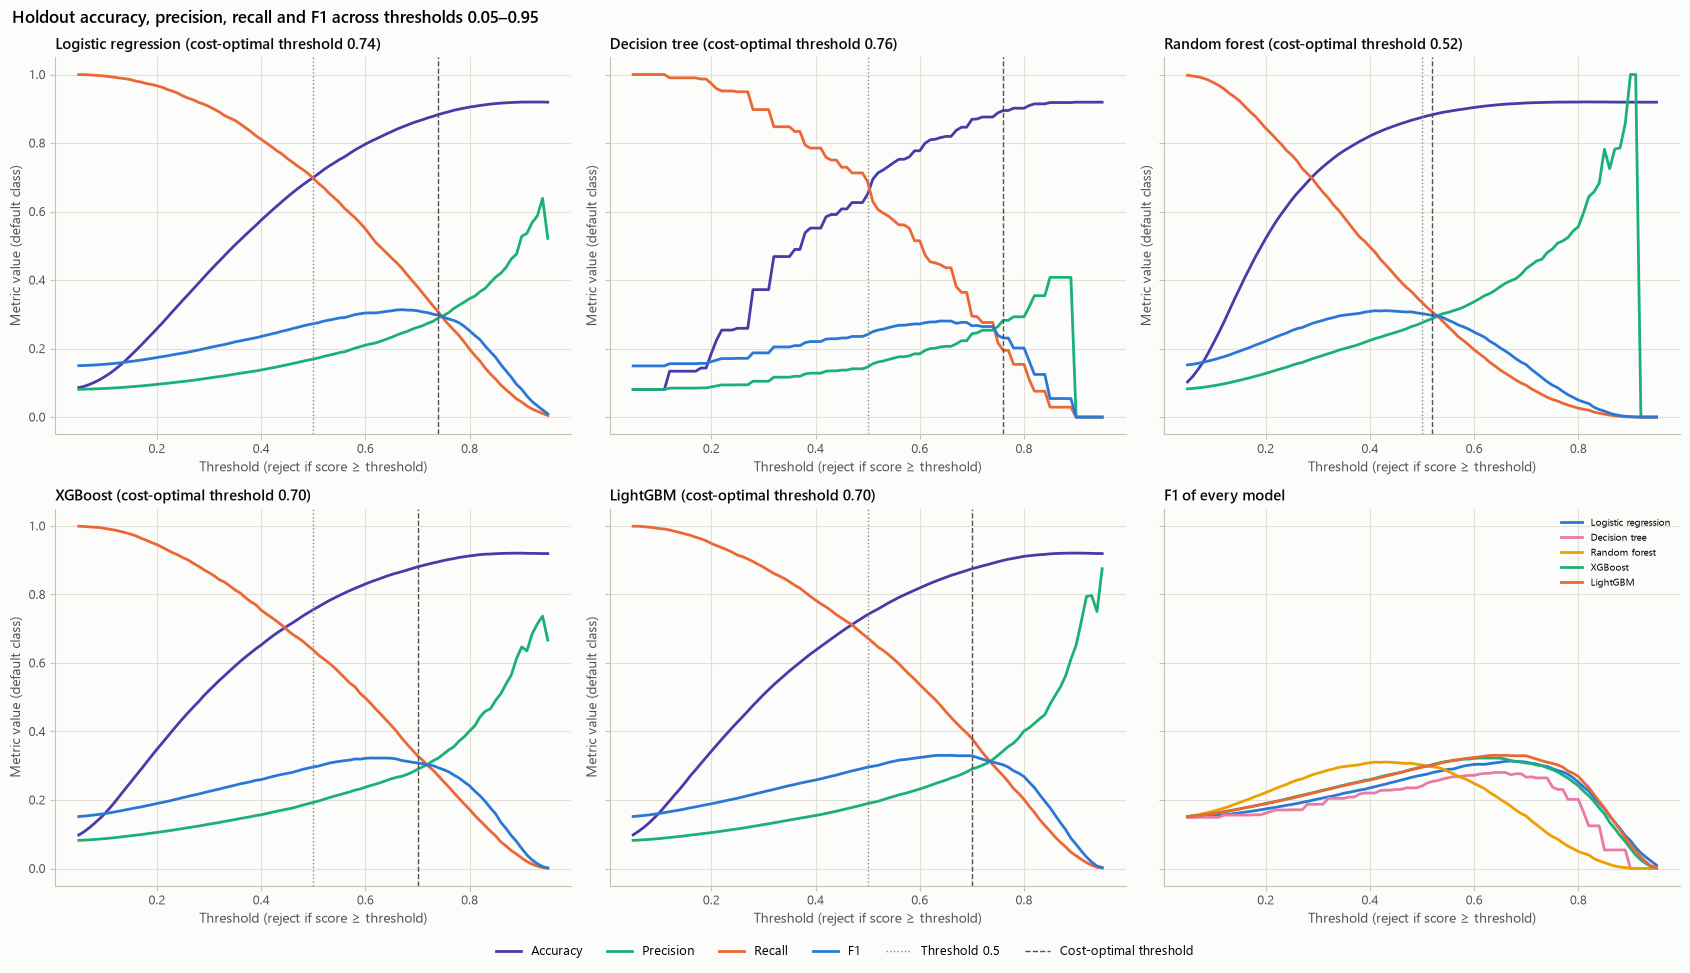

threshold with the highest holdout F1 per model (descriptive only):


,threshold,F1,Precision,Recall
model,,,,
Logistic regression,0.67,0.3136,0.2453,0.4346
Decision tree,0.64,0.2806,0.2051,0.4445
Random forest,0.43,0.3106,0.2386,0.4449
XGBoost,0.61,0.3225,0.2423,0.4822
LightGBM,0.66,0.3304,0.2640,0.4413


In [22]:
curves = pd.concat([metrics_by_threshold(y_holdout, holdout_probs[name]).assign(model=name) for name in MODEL_ORDER],
                   ignore_index=True)
curves = curves[["model"] + [c for c in curves.columns if c != "model"]]
METRIC_STYLE = {"Accuracy": SERIES[6], "Precision": SERIES[2], "Recall": SERIES[1], "F1": SERIES[0]}
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), sharey=True)
for ax, name in zip(axes.ravel(), MODEL_ORDER):
    d = curves[curves["model"] == name]
    for metric, color in METRIC_STYLE.items():
        ax.plot(d["threshold"], d[metric], color=color, label=metric)
    ax.axvline(0.5, color=MUTED, linestyle=":", linewidth=1, label="Threshold 0.5")
    ax.axvline(opt_thresholds[name], color=INK_2, linestyle="--", linewidth=1, label="Cost-optimal threshold")
    ax.set_title(f"{name} (cost-optimal threshold {opt_thresholds[name]:.2f})", loc="left", fontsize=11)
    ax.set_xlabel("Threshold (reject if score ≥ threshold)")
    ax.set_ylabel("Metric value (default class)")
ax = axes.ravel()[-1]
for name in MODEL_ORDER:
    d = curves[curves["model"] == name]
    ax.plot(d["threshold"], d["F1"], color=MODEL_COLORS[name], label=name)
ax.set_title("F1 of every model", loc="left", fontsize=11)
ax.set_xlabel("Threshold (reject if score ≥ threshold)")
ax.legend(loc="upper right", fontsize=7.5)
fig.suptitle("Holdout accuracy, precision, recall and F1 across thresholds 0.05–0.95", x=0.01, ha="left",
             fontweight="semibold")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=9, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout()
savefig(fig, "37_metrics_vs_threshold.png")
plt.show()
peak = curves.loc[curves.groupby("model")["F1"].idxmax(), ["model", "threshold", "F1", "Precision", "Recall"]]
print("threshold with the highest holdout F1 per model (descriptive only):")
display(peak.set_index("model").loc[MODEL_ORDER].round(4))

**Insight:** Raising the threshold flags fewer applicants: recall falls, accuracy climbs towards the 91.93% of approving everyone,
and precision rises but becomes noisy at high thresholds where few applicants are flagged. F1 peaks at an
intermediate threshold for every model, highest for LightGBM (0.3304 at 0.66), then XGBoost (0.3225 at 0.61),
logistic regression (0.3136 at 0.67), random forest (0.3106 at 0.43) and the decision tree (0.2806 at 0.64). The
cost-optimal thresholds chosen on training data are 0.04–0.12 higher than these holdout F1 peaks: the lender's costs,
not F1, decide how many applicants to reject.

## 12. Overfitting check: train vs cross-validation vs holdout AUC

Train AUC = the final model scored on the applicants it was trained on (in-sample). A model that memorises its
training data shows a large train−CV gap (**variance**); a model that is too simple shows low train *and* CV AUC
with a small gap (**bias**). The holdout AUC checks that CV was a fair estimate. The right panel uses the decision-tree
grid search (3-fold CV) to show the same effect as the tree grows deeper.

,train_AUC,CV_AUC_mean,holdout_AUC,train_minus_CV,train_minus_holdout,holdout_minus_CV
model,,,,,,
Logistic regression,0.7642,0.7600,0.7641,0.0042,0.0001,0.0041
Decision tree,0.7388,0.7266,0.7269,0.0122,0.0119,0.0003
Random forest,0.9353,0.7592,0.7618,0.1762,0.1735,0.0026
XGBoost,0.8628,0.7698,0.7744,0.0930,0.0884,0.0046
LightGBM,0.8433,0.7758,0.7819,0.0675,0.0614,0.0061


saved reports/figures/38_overfitting_check.png


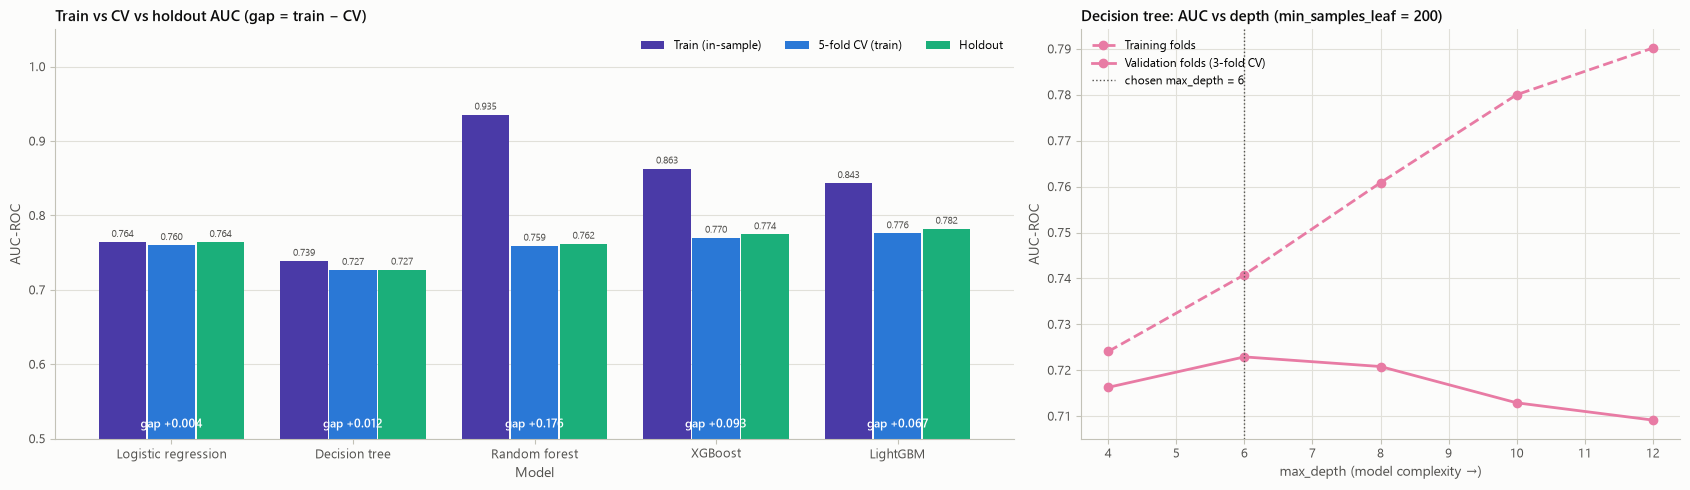

In [23]:
overfit = pd.DataFrame({
    name: {"train_AUC": roc_auc_score(y_train, models[name].predict_proba(X_train)[:, 1]),
           "CV_AUC_mean": cv_all[name]["auc_mean"], "holdout_AUC": metrics_table.loc[name, "AUC"]}
    for name in MODEL_ORDER}).T
overfit["train_minus_CV"] = overfit["train_AUC"] - overfit["CV_AUC_mean"]
overfit["train_minus_holdout"] = overfit["train_AUC"] - overfit["holdout_AUC"]
overfit["holdout_minus_CV"] = overfit["holdout_AUC"] - overfit["CV_AUC_mean"]
overfit.index.name = "model"
display(overfit.round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
x = np.arange(len(MODEL_ORDER))
for k, (col, label, color) in enumerate([("train_AUC", "Train (in-sample)", SERIES[6]),
                                         ("CV_AUC_mean", "5-fold CV (train)", SERIES[0]),
                                         ("holdout_AUC", "Holdout", SERIES[2])]):
    vals = overfit.loc[MODEL_ORDER, col].to_numpy()
    ax.bar(x + (k - 1) * 0.27, vals, width=0.26, color=color, label=label)
    for xi, v in zip(x + (k - 1) * 0.27, vals):
        ax.text(xi, v + 0.004, f"{v:.3f}", ha="center", va="bottom", fontsize=7.5, color=INK_2)
for xi, name in zip(x, MODEL_ORDER):
    ax.text(xi, 0.515, f"gap {overfit.loc[name, 'train_minus_CV']:+.3f}", ha="center", fontsize=8.5, color="white",
            fontweight="semibold")
ax.set_xticks(x, MODEL_ORDER)
ax.set_ylim(0.5, 1.05)
ax.set_title("Train vs CV vs holdout AUC (gap = train − CV)", loc="left", fontsize=11)
ax.set_xlabel("Model")
ax.set_ylabel("AUC-ROC")
ax.legend(loc="upper right", ncol=3, fontsize=8.5)
ax.grid(axis="x", visible=False)
ax = axes[1]
leaf = dt_best_params["min_samples_leaf"]
d = dt_results[dt_results["min_samples_leaf"] == leaf].sort_values("max_depth")
ax.plot(d["max_depth"], d["train_auc_mean"], marker="o", linestyle="--", color=MODEL_COLORS["Decision tree"],
        label="Training folds")
ax.plot(d["max_depth"], d["cv3_auc_mean"], marker="o", color=MODEL_COLORS["Decision tree"],
        label="Validation folds (3-fold CV)")
ax.axvline(dt_best_params["max_depth"], color=INK_2, linestyle=":", linewidth=1,
           label=f"chosen max_depth = {dt_best_params['max_depth']}")
ax.set_title(f"Decision tree: AUC vs depth (min_samples_leaf = {leaf})", loc="left", fontsize=11)
ax.set_xlabel("max_depth (model complexity →)")
ax.set_ylabel("AUC-ROC")
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
savefig(fig, "38_overfitting_check.png")
plt.show()

**Insight:** Train − CV AUC gaps: logistic regression 0.0042, decision tree 0.0122, random forest 0.1762, XGBoost 0.0930, LightGBM
0.0675; holdout AUC is within +0.0003 to +0.0061 of CV for every model, so CV was a fair estimate and no model fails on
new applicants.
- **High bias:** logistic regression and the depth-6 tree barely overfit, but their CV AUC stays well below the
  boosting models (0.7600 and 0.7266 vs 0.7758 for LightGBM); they are too simple to capture the non-linear patterns. The tree grid shows the other side: at depth 12 with leaves of 50 the
  training AUC reaches 0.8295 while CV AUC drops to 0.6792 (**high variance**).
- **Bagging reduces variance:** the random forest's fully grown trees memorise the training data (train AUC 0.9353),
  yet averaging 400 of them lifts CV AUC to 0.7592, far above a single tree.
- **Boosting with regularisation** (small trees, `reg_lambda`, feature sampling, early stopping) has moderate gaps
  and the best CV and holdout AUC: the best balance between bias and variance here.

## 13. Save models, metrics, curves and predictions

In [24]:
holdout_out = pd.DataFrame({ID: holdout[ID], TARGET: y_holdout, "AMT_CREDIT": credit_holdout})
for name in MODEL_ORDER:
    holdout_out[f"p_{SHORT[name]}"] = holdout_probs[name]

# Reproducibility check against the predictions saved by the previous run (before they are overwritten).
previous_path = PROCESSED_DIR / "holdout_predictions.parquet"
if previous_path.exists():
    previous = pd.read_parquet(previous_path)
    for col in [c for c in previous.columns if c.startswith("p_") and c in holdout_out]:
        diff = np.abs(previous[col].to_numpy() - holdout_out[col].to_numpy()).max()
        print(f"{col}: max |difference| vs the previously saved predictions = {diff:.2e}")

joblib.dump(logreg, MODELS_DIR / "logreg_pipeline.joblib")
joblib.dump(dt, MODELS_DIR / "dt_pipeline.joblib")
joblib.dump(rf, MODELS_DIR / "rf_pipeline.joblib", compress=3)
joblib.dump(xgb, MODELS_DIR / "xgb_model.joblib")
joblib.dump(lgbm, MODELS_DIR / "lgbm_model.joblib")
with open(MODELS_DIR / "lgbm_best_params.json", "w") as f:
    json.dump({"params": best_params, "cv_auc_mean": lgbm_cv["auc_mean"], "cv_auc_std": lgbm_cv["auc_std"],
               "cv_best_iterations": lgbm_cv["best_iterations"], "final_best_iteration": int(lgbm.best_iteration_),
               "features": FEATURES}, f, indent=2)
with open(MODELS_DIR / "dt_best_params.json", "w") as f:
    json.dump({"params": {k: int(v) for k, v in dt_best_params.items()}, "class_weight": "balanced",
               "depth": int(tree.get_depth()), "leaves": int(tree.get_n_leaves()),
               "cv_auc_mean": dt_cv["auc_mean"], "cv_auc_std": dt_cv["auc_std"]}, f, indent=2)
with open(MODELS_DIR / "rf_best_params.json", "w") as f:
    json.dump({"params": rf_best_params, "class_weight": "balanced_subsample", "max_samples": 0.5,
               "trials_run": len(rf_rows), "cv_auc_mean": rf_cv["auc_mean"], "cv_auc_std": rf_cv["auc_std"]}, f,
              indent=2)
with open(MODELS_DIR / "xgb_params.json", "w") as f:
    json.dump({"params": XGB_PARAMS, "final_best_iteration": int(xgb.best_iteration) + 1,
               "cv_auc_mean": xgb_cv["auc_mean"], "cv_auc_std": xgb_cv["auc_std"]}, f, indent=2)
with open(MODELS_DIR / "cost_thresholds.json", "w") as f:
    json.dump({"chosen_on": "train out-of-fold predictions", "LGD": 0.60, "MARGIN": 0.15,
               "thresholds": opt_thresholds}, f, indent=2)

metrics_table.round(6).to_csv(REPORTS_DIR / "metrics_table.csv")
final_table.round(6).to_csv(REPORTS_DIR / "metrics_table_final.csv", index=False)
cv_summary.round(6).to_csv(REPORTS_DIR / "cv_results.csv")
overfit.round(6).to_csv(REPORTS_DIR / "overfitting_check.csv")
curves.to_parquet(PROCESSED_DIR / "threshold_curves.parquet", index=False)

# Out-of-fold predictions on train: LightGBM (used by notebook 04) and all models (threshold selection).
pd.DataFrame({ID: train[ID], TARGET: y_train, "oof_lgbm": lgbm_cv["oof"]}).to_parquet(
    PROCESSED_DIR / "oof_lgbm.parquet", index=False)
oof_out = pd.DataFrame({ID: train[ID], TARGET: y_train, "AMT_CREDIT": credit_train})
for name in MODEL_ORDER:
    oof_out[f"oof_{SHORT[name]}"] = cv_all[name]["oof"]
oof_out.to_parquet(PROCESSED_DIR / "oof_predictions.parquet", index=False)
holdout_out.to_parquet(PROCESSED_DIR / "holdout_predictions.parquet", index=False)

for p in sorted(MODELS_DIR.iterdir()):
    print(f"models/{p.name}  {p.stat().st_size / 1024 ** 2:.1f} MB")
print("reports/: metrics_table.csv, metrics_table_final.csv, cv_results.csv, overfitting_check.csv, "
      "lgbm/dt/rf search results")
print(f"data/processed/: threshold_curves.parquet ({len(curves):,} rows), oof_lgbm.parquet, oof_predictions.parquet, "
      f"holdout_predictions.parquet ({holdout_out.shape[0]:,} rows x {holdout_out.shape[1]} columns)")

p_logreg: max |difference| vs the previously saved predictions = 0.00e+00
p_lgbm: max |difference| vs the previously saved predictions = 0.00e+00
p_xgb: max |difference| vs the previously saved predictions = 0.00e+00


models/cost_thresholds.json  0.0 MB
models/dt_best_params.json  0.0 MB
models/dt_pipeline.joblib  0.0 MB
models/lgbm_best_params.json  0.0 MB
models/lgbm_model.joblib  3.9 MB
models/logreg_pipeline.joblib  0.0 MB
models/rf_best_params.json  0.0 MB
models/rf_pipeline.joblib  57.0 MB
models/xgb_model.joblib  2.2 MB
models/xgb_params.json  0.0 MB
reports/: metrics_table.csv, metrics_table_final.csv, cv_results.csv, overfitting_check.csv, lgbm/dt/rf search results
data/processed/: threshold_curves.parquet (455 rows), oof_lgbm.parquet, oof_predictions.parquet, holdout_predictions.parquet (61,502 rows x 8 columns)


## 14. Summary

- **Best model: LightGBM.** Holdout AUC 0.7819, Gini 0.5638, PR-AUC 0.2818, KS 0.4237; at its cost-optimal threshold
  (0.70) it has the highest precision (0.2903), recall (0.3797) and F1 (0.3290) and saves 14.04% of expected cost vs
  approving everyone. XGBoost is second on every ranking metric (AUC 0.7744).
- **Accuracy is misleading:** approving everyone is 91.93% accurate; the most "accurate" models (random forest at 0.5,
  decision tree at its cost-optimal threshold) are the ones that flag the fewest applicants.
- **Thresholds matter as much as models:** at 0.5 four of the five models cost more than approving everyone.
- **Bias–variance:** the linear model and the shallow tree underfit, deep trees overfit, bagging and boosting control
  the variance; holdout AUC stays within 0.0061 of CV for every model.
- Saved: `reports/metrics_table_final.csv` (one row per model per threshold type), `reports/cv_results.csv`,
  `reports/overfitting_check.csv`, `data/processed/threshold_curves.parquet`, `holdout_predictions.parquet`,
  `oof_predictions.parquet`, and all five models in `models/`.